In [118]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score
df=pd.read_csv("/content/sample_data/california_housing_test.csv")
df.head()
df.tail()
df.shape
df.size
df.corr()
X=df[['median_income', 'total_rooms', 'households', 'housing_median_age', 'latitude', 'longitude']]
y=df['median_house_value']

x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2)

model=LinearRegression()
model.fit(x_train,y_train)
ypred=model.predict(x_test)
ypred
mse=mean_squared_error(y_test,ypred)
mse
r2=r2_score(y_test,ypred)
r2

0.5996054570645775

### Logistic Regression on Iris Dataset


In [119]:
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

iris = load_iris()
X_iris, y_iris = iris.data, iris.target

# For simplicity, let's use the first two classes (Setosa and Versicolor) for binary classification.
X_binary_lr = X_iris[y_iris < 2]
y_binary_lr = y_iris[y_iris < 2]

x_train_lr, x_test_lr, y_train_lr, y_test_lr = train_test_split(X_binary_lr, y_binary_lr, test_size=0.3, random_state=42)

print(f"Shape of X_train for Logistic Regression: {x_train_lr.shape}")
print(f"Shape of y_train for Logistic Regression: {y_train_lr.shape}")
print(f"Shape of X_test for Logistic Regression: {x_test_lr.shape}")
print(f"Shape of y_test for Logistic Regression: {y_test_lr.shape}")

# Initialize the Logistic Regression model
log_reg_model = LogisticRegression(random_state=42)

# Train the model
log_reg_model.fit(x_train_lr, y_train_lr)

print("Logistic Regression model trained successfully!")

# Make predictions on the test set
y_pred_lr = log_reg_model.predict(x_test_lr)

# Evaluate the model
accuracy_lr = accuracy_score(y_test_lr, y_pred_lr)
print(f"Logistic Regression Model Accuracy on Iris (binary): {accuracy_lr:.4f}")

Shape of X_train for Logistic Regression: (70, 4)
Shape of y_train for Logistic Regression: (70,)
Shape of X_test for Logistic Regression: (30, 4)
Shape of y_test for Logistic Regression: (30,)
Logistic Regression model trained successfully!
Logistic Regression Model Accuracy on Iris (binary): 1.0000


### Decision Tree Regressor

Decision Trees are non-parametric supervised learning methods used for both classification and regression tasks. They work by splitting the data into subsets based on feature values, forming a tree-like structure of decisions.

For regression, the predicted value for an instance is the average of the target values of the training instances that reach the same leaf node.

In [123]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

# We will reuse the pre-processed X and y from the California housing dataset
# X contains features like median_income, total_rooms, etc.
# y contains median_house_value

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

# Split the data into training and testing sets
X_train_dt, X_test_dt, y_train_dt, y_test_dt = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the Decision Tree Regressor model
dt_model = DecisionTreeRegressor(random_state=42)

# Train the model
dt_model.fit(X_train_dt, y_train_dt)

print("Decision Tree Regressor model trained successfully!")

# Make predictions on the test set
y_pred_dt = dt_model.predict(X_test_dt)

# Evaluate the model
mse_dt = mean_squared_error(y_test_dt, y_pred_dt)
r2_dt = r2_score(y_test_dt, y_pred_dt)

print(f"\nDecision Tree Regressor Mean Squared Error: {mse_dt:.2f}")
print(f"Decision Tree Regressor R-squared: {r2_dt:.4f}")

Features shape: (3000, 6)
Target shape: (3000,)
Decision Tree Regressor model trained successfully!

Decision Tree Regressor Mean Squared Error: 6971058117.38
Decision Tree Regressor R-squared: 0.4465


### Random Forest Regressor

A Random Forest is an ensemble learning method that operates by constructing a multitude of decision trees during training. For regression tasks, the output of the Random Forest is the mean or average prediction of the individual trees.

Random Forests generally provide higher accuracy than single decision trees and are robust to overfitting.

In [122]:
from sklearn.ensemble import RandomForestRegressor

# We will reuse the same X_train_dt, X_test_dt, y_train_dt, y_test_dt splits from the Decision Tree Regressor section.

# Initialize the Random Forest Regressor model
# n_estimators: The number of trees in the forest.
# random_state: For reproducibility.
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1) # n_jobs=-1 uses all available cores

# Train the model
rf_model.fit(X_train_dt, y_train_dt)

print("Random Forest Regressor model trained successfully!")

# Make predictions on the test set
y_pred_rf = rf_model.predict(X_test_dt)

# Evaluate the model
mse_rf = mean_squared_error(y_test_dt, y_pred_rf)
r2_rf = r2_score(y_test_dt, y_pred_rf)

print(f"\nRandom Forest Regressor Mean Squared Error: {mse_rf:.2f}")
print(f"Random Forest Regressor R-squared: {r2_rf:.4f}")

Random Forest Regressor model trained successfully!

Random Forest Regressor Mean Squared Error: 3482905068.49
Random Forest Regressor R-squared: 0.7234


### K-Means Clustering

K-Means is a popular unsupervised learning algorithm used for partitioning `n` observations into `k` clusters. Each observation belongs to the cluster with the nearest mean (centroid), serving as a prototype of the cluster. This results in a partitioning of the data space into Voronoi cells.

K-Means clustering performed successfully!
First 5 rows with cluster labels:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,cluster
0,-122.05,37.37,27.0,3885.0,661.0,1537.0,606.0,6.6085,344700.0,0
1,-118.30,34.26,43.0,1510.0,310.0,809.0,277.0,3.5990,176500.0,1
2,-117.81,33.78,27.0,3589.0,507.0,1484.0,495.0,5.7934,270500.0,0
3,-118.36,33.82,28.0,67.0,15.0,49.0,11.0,6.1359,330000.0,1
4,-119.67,36.33,19.0,1241.0,244.0,850.0,237.0,2.9375,81700.0,1



Cluster Summary (Mean of Features per Cluster):


,median_income,total_rooms,households,housing_median_age,latitude,longitude
cluster,,,,,,
0,4.380067,4402.336538,797.475275,22.186813,35.686648,-119.650165
1,3.580401,1720.851969,346.933454,31.528746,35.636627,-119.593291
2,5.143186,12578.936508,1949.174603,11.698413,34.999683,-118.741270


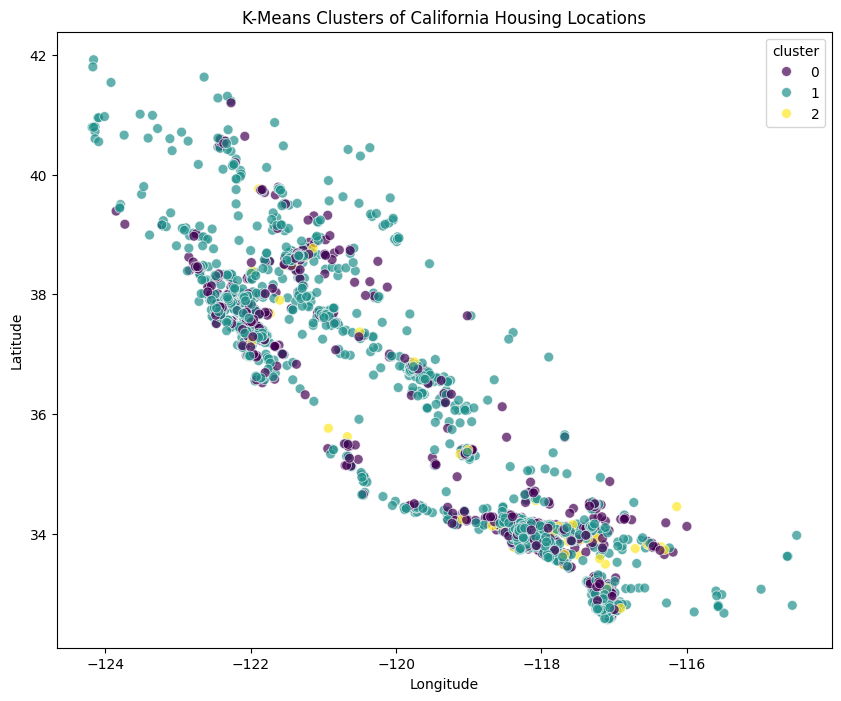

In [127]:
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings('ignore', category=FutureWarning) # Suppress KMeans FutureWarning

# We will use the features (X) from our California housing dataset for clustering

# Initialize KMeans with 3 clusters for demonstration
# random_state ensures reproducibility
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10) # n_init=10 to explicitly set the number of initializations

# Fit KMeans to the data
kmeans.fit(X)

# Get the cluster labels for each data point
cluster_labels = kmeans.labels_

# Add the cluster labels to our DataFrame for analysis
df['cluster'] = cluster_labels

print("K-Means clustering performed successfully!")
print("First 5 rows with cluster labels:")
display(df.head())

# Analyze cluster characteristics
cluster_summary = df.groupby('cluster')[X.columns].mean()
print("\nCluster Summary (Mean of Features per Cluster):")
display(cluster_summary)

# You can also visualize the clusters if you want, for example using latitude and longitude
plt.figure(figsize=(10, 8))
sns.scatterplot(x='longitude', y='latitude', hue='cluster', data=df, palette='viridis', s=50, alpha=0.7)
plt.title('K-Means Clusters of California Housing Locations')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

### Hierarchical Clustering

Hierarchical clustering is another method for grouping data points. Unlike K-Means, which requires you to specify the number of clusters in advance, hierarchical clustering builds a hierarchy of clusters. This hierarchy can be visualized as a dendrogram.

There are two main types:
1.  **Agglomerative (bottom-up):** Each data point starts as its own cluster, and then pairs of clusters are merged as one moves up the hierarchy.
2.  **Divisive (top-down):** All data points start in one cluster, and then the cluster is recursively split as one moves down the hierarchy.

We will use Agglomerative Clustering. We'll also use a dendrogram to help us decide on an appropriate number of clusters, and then apply the clustering to the California housing data.

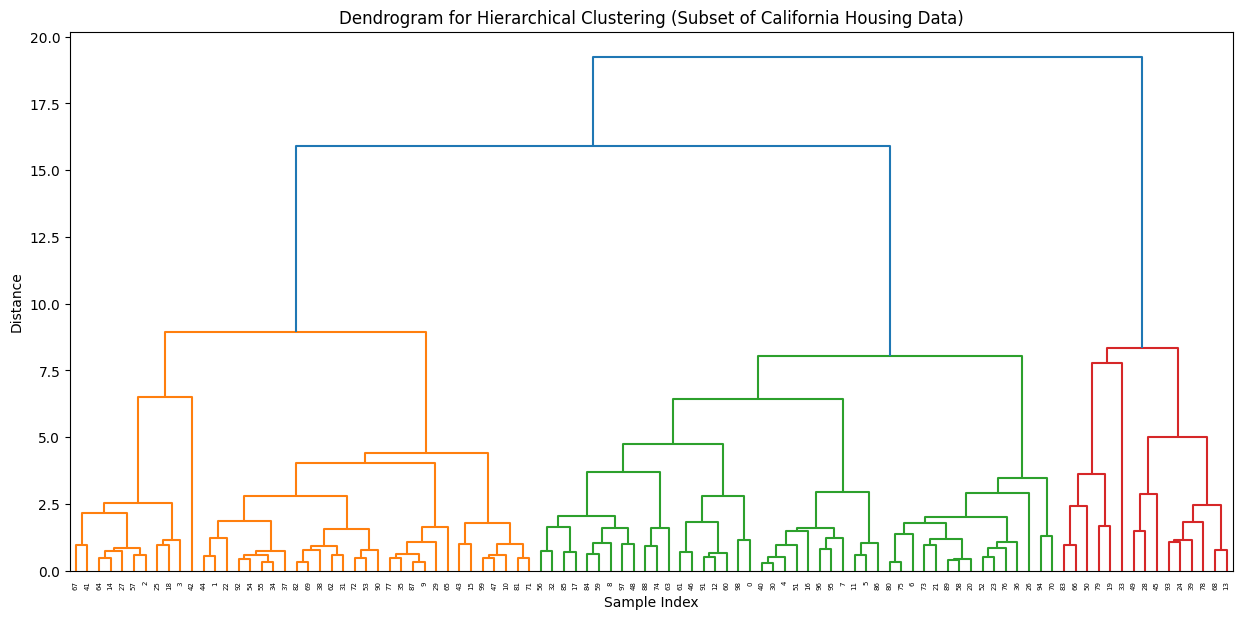

Dendrogram plotted. You can use this to visually determine a suitable number of clusters by looking for large vertical gaps.


In [136]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler

# It's important to scale the data for hierarchical clustering as well
scaler_hc = StandardScaler()
X_scaled_hc = scaler_hc.fit_transform(X)

# For visualization, let's take a smaller subset of the scaled data
# Dendrograms can become very cluttered with too many data points
X_subset_hc = X_scaled_hc[:100] # Take the first 100 samples for dendrogram

# Perform hierarchical clustering (linkage) on the subset
# 'ward' linkage minimizes the variance of the clusters being merged.
linked_hc = linkage(X_subset_hc, method='ward')

# Plot the dendrogram
plt.figure(figsize=(15, 7))
dendrogram(linked_hc,
           orientation='top',
           distance_sort='descending',
           show_leaf_counts=True)
plt.title('Dendrogram for Hierarchical Clustering (Subset of California Housing Data)')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.show()

print("Dendrogram plotted. You can use this to visually determine a suitable number of clusters by looking for large vertical gaps.")

Based on the dendrogram, we can decide on a number of clusters by cutting the tree at a certain height. For demonstration, let's assume we choose to form 3 clusters, similar to our K-Means example. We'll then apply `AgglomerativeClustering` to the full scaled dataset.

Hierarchical Clustering performed successfully!
First 5 rows with hierarchical cluster labels:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,cluster,hierarchical_cluster
0,-122.05,37.37,27.0,3885.0,661.0,1537.0,606.0,6.6085,344700.0,0,1
1,-118.30,34.26,43.0,1510.0,310.0,809.0,277.0,3.5990,176500.0,1,0
2,-117.81,33.78,27.0,3589.0,507.0,1484.0,495.0,5.7934,270500.0,0,0
3,-118.36,33.82,28.0,67.0,15.0,49.0,11.0,6.1359,330000.0,1,0
4,-119.67,36.33,19.0,1241.0,244.0,850.0,237.0,2.9375,81700.0,1,0



Hierarchical Cluster Summary (Mean of Features per Cluster):


,median_income,total_rooms,households,housing_median_age,latitude,longitude
hierarchical_cluster,,,,,,
0,3.862441,2192.356454,429.003619,29.797949,34.076918,-118.156713
1,3.691012,2411.438449,448.430860,29.404722,37.995734,-121.789966
2,4.104795,8357.967949,1452.621795,14.467949,34.254487,-118.082500


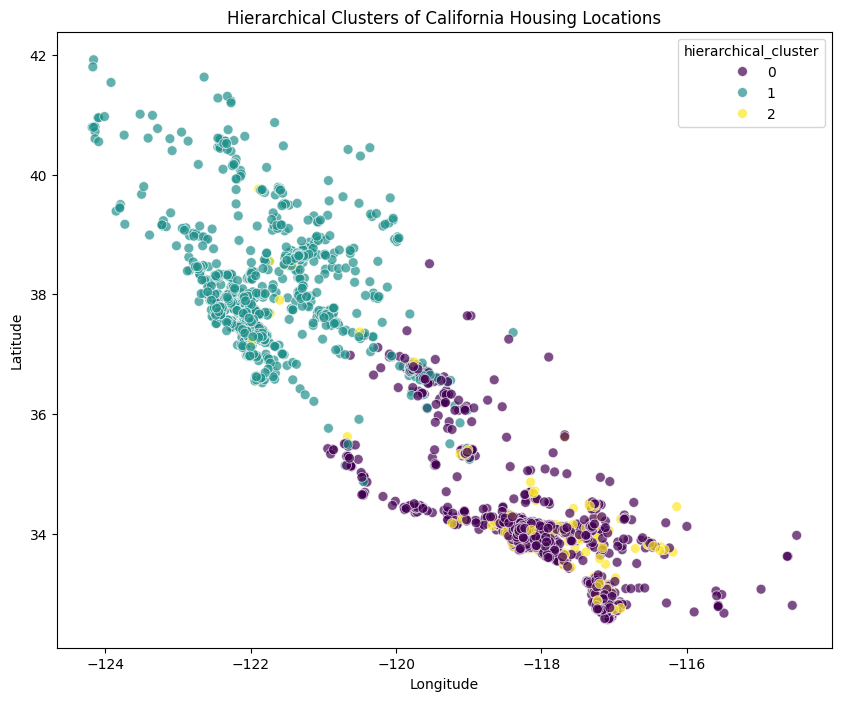

In [137]:
from sklearn.cluster import AgglomerativeClustering

# Apply AgglomerativeClustering to the full scaled dataset
# n_clusters: The number of clusters to form.
# linkage: Which linkage criterion to use ('ward' minimizes variance within clusters).
agglomerative_cluster = AgglomerativeClustering(n_clusters=3, linkage='ward')

# Fit and get cluster labels
hc_cluster_labels = agglomerative_cluster.fit_predict(X_scaled_hc)

# Add the cluster labels to our DataFrame for analysis
df['hierarchical_cluster'] = hc_cluster_labels

print("Hierarchical Clustering performed successfully!")
print("First 5 rows with hierarchical cluster labels:")
display(df.head())

# Analyze cluster characteristics
hc_cluster_summary = df.groupby('hierarchical_cluster')[X.columns].mean()
print("\nHierarchical Cluster Summary (Mean of Features per Cluster):")
display(hc_cluster_summary)

# Visualize the clusters using latitude and longitude
plt.figure(figsize=(10, 8))
sns.scatterplot(x='longitude', y='latitude', hue='hierarchical_cluster', data=df, palette='viridis', s=50, alpha=0.7)
plt.title('Hierarchical Clusters of California Housing Locations')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

### XGBoost Regressor

Now, let's move on to **XGBoost (Extreme Gradient Boosting)**. XGBoost is an optimized distributed gradient boosting library designed to be highly efficient, flexible, and portable. It implements machine learning algorithms under the Gradient Boosting framework. XGBoost provides a parallel tree boosting (also known as GBDT, GBM) that solves many data science problems in a fast and accurate way.

We'll use it to predict `median_house_value` using the same features as before, and potentially even include the new 'cluster' feature we just created if we find it useful.

In [126]:
import xgboost as xgb

# For XGBoost, we can use the original features X and target y
# Optionally, we could add the 'cluster' feature to X if it improves performance
# For now, let's stick to the original X for direct comparison with previous models.

# Reuse the existing train-test split (X_train_dt, X_test_dt, y_train_dt, y_test_dt) from Decision Tree/Random Forest

# Initialize the XGBoost Regressor model
# n_estimators: Number of boosting rounds (trees)
# learning_rate: Step size shrinkage to prevent overfitting
# random_state: For reproducibility
xgb_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, n_jobs=-1)

# Train the model
xgb_model.fit(X_train_dt, y_train_dt)

print("XGBoost Regressor model trained successfully!")

# Make predictions on the test set
y_pred_xgb = xgb_model.predict(X_test_dt)

# Evaluate the model
mse_xgb = mean_squared_error(y_test_dt, y_pred_xgb)
r2_xgb = r2_score(y_test_dt, y_pred_xgb)

print(f"\nXGBoost Regressor Mean Squared Error: {mse_xgb:.2f}")
print(f"XGBoost Regressor R-squared: {r2_xgb:.4f}")

XGBoost Regressor model trained successfully!

XGBoost Regressor Mean Squared Error: 3231547893.43
XGBoost Regressor R-squared: 0.7434


### Principal Component Analysis (PCA)

PCA is a statistical procedure that uses an orthogonal transformation to convert a set of observations of possibly correlated variables into a set of values of linearly uncorrelated variables called principal components. The number of principal components is less than or equal to the number of original variables. This transformation is defined in such a way that the first principal component has the largest possible variance, and each succeeding component in turn has the highest variance possible under the constraint that it is orthogonal to the preceding components.

In [128]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# It's crucial to scale the data before applying PCA, as PCA is sensitive to the variance of features.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Initialize PCA. We'll start by reducing to 2 components for visualization, but you can choose more.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(f"Original feature shape: {X_scaled.shape}")
print(f"Transformed feature shape (PCA): {X_pca.shape}")

# Explained variance ratio for each component
print(f"Explained variance ratio per component: {pca.explained_variance_ratio_}")
print(f"Total explained variance: {pca.explained_variance_ratio_.sum():.2f}")

# Create a DataFrame for PCA results (optional, for easier inspection)
df_pca = pd.DataFrame(data=X_pca, columns=['principal_component_1', 'principal_component_2'])
df_pca['median_house_value'] = y.reset_index(drop=True) # Add target for potential visualization

print("\nFirst 5 rows of PCA-transformed data:")
display(df_pca.head())

Original feature shape: (3000, 6)
Transformed feature shape (PCA): (3000, 2)
Explained variance ratio per component: [0.3680635 0.3135732]
Total explained variance: 0.68

First 5 rows of PCA-transformed data:


,principal_component_1,principal_component_2,median_house_value
0,0.347118,1.672033,344700.0
1,-0.734630,-1.285199,176500.0
2,0.997550,-0.958832,270500.0
3,-0.826359,-1.455276,330000.0
4,-0.680934,0.032924,81700.0


### Support Vector Regressor (SVR)

Support Vector Machines (SVMs) are powerful and versatile Machine Learning models, capable of performing linear or non-linear classification, regression, and even outlier detection. For regression, SVR tries to find a function that deviates from the true targets by no more than a certain amount (epsilon), while also being as flat as possible (minimizing the coefficients). Non-linear relationships can be captured using kernel tricks.

We'll train an SVR model using the PCA-transformed data.

In [129]:
from sklearn.svm import SVR

# Since PCA transformed our features, we need to split the new X_pca data
# We'll use the target 'y' as before

X_train_svr, X_test_svr, y_train_svr, y_test_svr = train_test_split(X_pca, y, test_size=0.2, random_state=42)

# Initialize the Support Vector Regressor model
# SVR can be computationally expensive on large datasets, so a small kernel like 'linear' is a good start.
# For better performance on non-linear data, 'rbf' kernel is often used, but requires more tuning.
svr_model = SVR(kernel='linear')

# Train the model
# Note: SVR can be sensitive to scaling of the target variable as well, but for now we'll use original y.
svr_model.fit(X_train_svr, y_train_svr)

print("Support Vector Regressor model trained successfully!")

# Make predictions on the test set
y_pred_svr = svr_model.predict(X_test_svr)

# Evaluate the model
mse_svr = mean_squared_error(y_test_svr, y_pred_svr)
r2_svr = r2_score(y_test_svr, y_pred_svr)

print(f"\nSupport Vector Regressor Mean Squared Error: {mse_svr:.2f}")
print(f"Support Vector Regressor R-squared: {r2_svr:.4f}")

Support Vector Regressor model trained successfully!

Support Vector Regressor Mean Squared Error: 12995705489.32
Support Vector Regressor R-squared: -0.0319


### Decision Tree Classifier

Similar to the Decision Tree Regressor, a Decision Tree Classifier works by recursively splitting the data based on features to classify instances into discrete classes. It builds a tree-like model of decisions, where each internal node represents a test on an attribute, each branch represents an outcome of the test, and each leaf node represents a class label.

We'll use the well-known Iris dataset, which has three classes of flowers, to demonstrate its classification power.

In [132]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.datasets import load_iris

# Load the Iris dataset
iris = load_iris()
X_iris_clf, y_iris_clf = iris.data, iris.target

# Split the dataset into training and testing sets
X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris_clf, y_iris_clf, test_size=0.3, random_state=42, stratify=y_iris_clf # stratify ensures balanced classes in splits
)

print(f"Shape of X_train for Iris Classification: {X_train_iris.shape}")
print(f"Shape of y_train for Iris Classification: {y_train_iris.shape}")
print(f"Shape of X_test for Iris Classification: {X_test_iris.shape}")
print(f"Shape of y_test for Iris Classification: {y_test_iris.shape}")

# Initialize the Decision Tree Classifier model
dt_classifier = DecisionTreeClassifier(random_state=42)

# Train the model
dt_classifier.fit(X_train_iris, y_train_iris)

print("Decision Tree Classifier model trained successfully!")

# Make predictions on the test set
y_pred_iris = dt_classifier.predict(X_test_iris)

# Evaluate the model
accuracy_iris = accuracy_score(y_test_iris, y_pred_iris)

print(f"\nDecision Tree Classifier Accuracy on Iris: {accuracy_iris:.4f}")
print("\nClassification Report:")
print(classification_report(y_test_iris, y_pred_iris, target_names=iris.target_names))

Shape of X_train for Iris Classification: (105, 4)
Shape of y_train for Iris Classification: (105,)
Shape of X_test for Iris Classification: (45, 4)
Shape of y_test for Iris Classification: (45,)
Decision Tree Classifier model trained successfully!

Decision Tree Classifier Accuracy on Iris: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.80      0.89        15
   virginica       0.83      1.00      0.91        15

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45



### Random Forest Classifier

Just like its regression counterpart, the Random Forest Classifier is an ensemble learning method that constructs a multitude of decision trees during training. For classification, the output of the Random Forest is the class selected by most trees (i.e., by majority vote).

Random Forests generally provide higher accuracy and are more robust to overfitting compared to single decision trees. We'll apply it to the same Iris dataset.

In [133]:
from sklearn.ensemble import RandomForestClassifier

# We'll reuse the same train-test splits (X_train_iris, X_test_iris, y_train_iris, y_test_iris)
# from the Decision Tree Classifier section.

# Initialize the Random Forest Classifier model
# n_estimators: The number of trees in the forest.
# random_state: For reproducibility.
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1) # n_jobs=-1 uses all available cores

# Train the model
rf_classifier.fit(X_train_iris, y_train_iris)

print("Random Forest Classifier model trained successfully!")

# Make predictions on the test set
y_pred_rf_iris = rf_classifier.predict(X_test_iris)

# Evaluate the model
accuracy_rf_iris = accuracy_score(y_test_iris, y_pred_rf_iris)

print(f"\nRandom Forest Classifier Accuracy on Iris: {accuracy_rf_iris:.4f}")
print("\nClassification Report:")
print(classification_report(y_test_iris, y_pred_rf_iris, target_names=iris.target_names))

Random Forest Classifier model trained successfully!

Random Forest Classifier Accuracy on Iris: 0.8889

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.78      0.93      0.85        15
   virginica       0.92      0.73      0.81        15

    accuracy                           0.89        45
   macro avg       0.90      0.89      0.89        45
weighted avg       0.90      0.89      0.89        45



### XGBoost Classifier

Similar to its regression counterpart, XGBoost can also be used for classification tasks. It leverages the power of gradient boosting to build a strong predictive model by combining multiple weak prediction models, typically decision trees. It is known for its high performance and efficiency.

We will apply the XGBoost Classifier to the Iris dataset, using the same train-test splits (`X_train_iris`, `X_test_iris`, `y_train_iris`, `y_test_iris`) that were used for the Decision Tree and Random Forest Classifiers.

In [134]:
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report

# We'll reuse the same train-test splits (X_train_iris, X_test_iris, y_train_iris, y_test_iris)
# from the Decision Tree Classifier section.

# Initialize the XGBoost Classifier model
# n_estimators: Number of boosting rounds (trees)
# learning_rate: Step size shrinkage to prevent overfitting
# use_label_encoder=False and eval_metric for deprecation warnings
xgb_classifier = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    use_label_encoder=False, # Suppress future warning
    eval_metric='mlogloss' # LogLoss for multi-class classification
)

# Train the model
xgb_classifier.fit(X_train_iris, y_train_iris)

print("XGBoost Classifier model trained successfully!")

# Make predictions on the test set
y_pred_xgb_iris = xgb_classifier.predict(X_test_iris)

# Evaluate the model
accuracy_xgb_iris = accuracy_score(y_test_iris, y_pred_xgb_iris)

print(f"\nXGBoost Classifier Accuracy on Iris: {accuracy_xgb_iris:.4f}")
print("\nClassification Report:")
print(classification_report(y_test_iris, y_pred_xgb_iris, target_names=iris.target_names))

XGBoost Classifier model trained successfully!

XGBoost Classifier Accuracy on Iris: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.88      0.93      0.90        15
   virginica       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45



/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [04:43:10] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


### Support Vector Machine (SVM) Classifier

Support Vector Machines (SVMs) are powerful and versatile machine learning models capable of performing linear or non-linear classification, regression, and even outlier detection. For classification, an SVM constructs a hyperplane or set of hyperplanes in a high-dimensional space, which can be used for classification, regression, or other tasks like outlier detection. Intuitively, a good separation is achieved by the hyperplane that has the largest distance to the nearest training-data point of any class (so-called functional margin), since in general the larger the margin, the lower the generalization error of the classifier.

We will apply the SVM Classifier to the Iris dataset, using the same train-test splits (`X_train_iris`, `X_test_iris`, `y_train_iris`, `y_test_iris`) that were used for the Decision Tree, Random Forest, and XGBoost Classifiers.

In [135]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# We'll reuse the same train-test splits (X_train_iris, X_test_iris, y_train_iris, y_test_iris)
# from the previous classification sections.

# Initialize the Support Vector Classifier model
# kernel: Specifies the kernel type to be used in the algorithm ('linear', 'rbf', 'poly', etc.)
# random_state: For reproducibility.
svc_classifier = SVC(kernel='linear', random_state=42)

# Train the model
svc_classifier.fit(X_train_iris, y_train_iris)

print("Support Vector Classifier model trained successfully!")

# Make predictions on the test set
y_pred_svc_iris = svc_classifier.predict(X_test_iris)

# Evaluate the model
accuracy_svc_iris = accuracy_score(y_test_iris, y_pred_svc_iris)

print(f"\nSupport Vector Classifier Accuracy on Iris: {accuracy_svc_iris:.4f}")
print("\nClassification Report:")
print(classification_report(y_test_iris, y_pred_svc_iris, target_names=iris.target_names))

Support Vector Classifier model trained successfully!

Support Vector Classifier Accuracy on Iris: 1.0000

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      1.00      1.00        15
   virginica       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



### DBSCAN Clustering

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) is a non-parametric, density-based clustering algorithm. Unlike K-Means, it does not require specifying the number of clusters beforehand. It can find arbitrarily shaped clusters and is able to identify noise points.

The core idea is to group together data points that are closely packed together, marking as outliers points that lie alone in low-density regions. It defines clusters as continuous regions of high density.

Key parameters:
- `eps`: The maximum distance between two samples for one to be considered as in the neighborhood of the other.
- `min_samples`: The number of samples (or total weight) in a neighborhood for a point to be considered as a core point. This includes the point itself.

DBSCAN clustering performed successfully!
First 5 rows with DBSCAN cluster labels:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,cluster,hierarchical_cluster,dbscan_cluster
0,-122.05,37.37,27.0,3885.0,661.0,1537.0,606.0,6.6085,344700.0,0,1,-1
1,-118.30,34.26,43.0,1510.0,310.0,809.0,277.0,3.5990,176500.0,1,0,0
2,-117.81,33.78,27.0,3589.0,507.0,1484.0,495.0,5.7934,270500.0,0,0,0
3,-118.36,33.82,28.0,67.0,15.0,49.0,11.0,6.1359,330000.0,1,0,-1
4,-119.67,36.33,19.0,1241.0,244.0,850.0,237.0,2.9375,81700.0,1,0,-1



DBSCAN Cluster Summary (Mean of Features per Cluster, excluding noise):


,median_income,total_rooms,households,housing_median_age,latitude,longitude
dbscan_cluster,,,,,,
0,3.522877,1922.380100,402.350249,33.621891,33.883522,-118.039771
1,3.821906,1890.240223,369.620112,39.276536,37.716369,-122.154106
2,4.467260,3896.800000,680.800000,16.700000,32.867000,-117.089000
3,5.998327,1715.636364,279.000000,17.181818,37.360000,-121.922727
4,2.326554,1626.038462,318.076923,32.250000,36.559808,-119.640962
5,2.383640,3360.000000,946.300000,27.200000,34.010000,-118.277000
6,2.034967,998.000000,191.555556,47.555556,38.716667,-121.365556


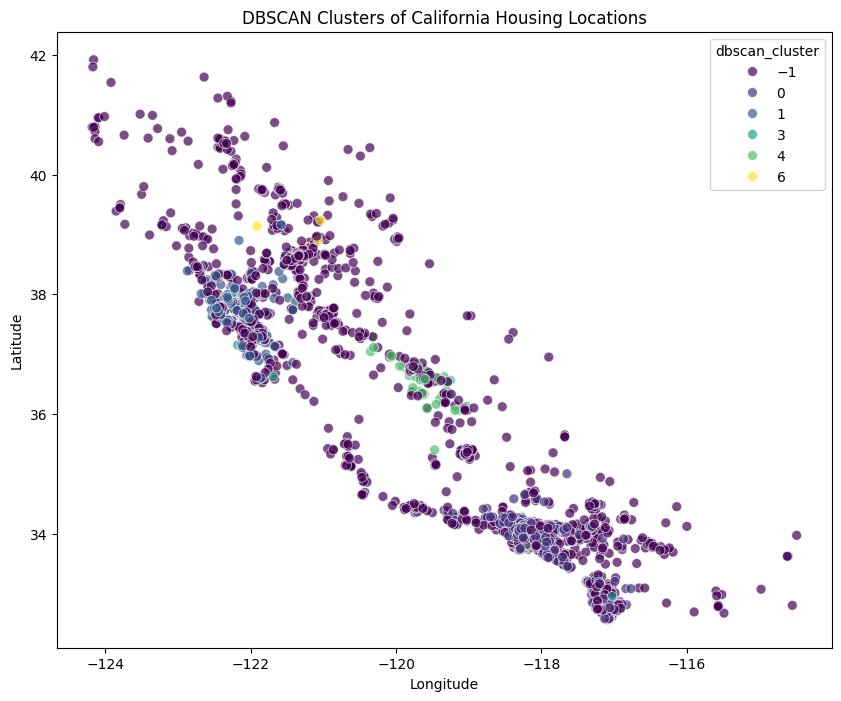

In [138]:
from sklearn.cluster import DBSCAN

# We'll use the scaled data (X_scaled) which was prepared for PCA.
# DBSCAN is sensitive to scaling.

# Initialize DBSCAN model
# The parameters 'eps' and 'min_samples' are crucial and often require tuning.
# Let's start with some initial values. 'eps' can be determined by a k-distance graph (elbow method).
# 'min_samples' is often set to 2 * number_of_features or higher.
dbscan = DBSCAN(eps=0.5, min_samples=10) # Using 2 * 6 features = 12 as a starting point, trying 10.

# Fit the model and get cluster labels
dbscan_cluster_labels = dbscan.fit_predict(X_scaled)

# Add the cluster labels to our DataFrame
df['dbscan_cluster'] = dbscan_cluster_labels

print("DBSCAN clustering performed successfully!")
print("First 5 rows with DBSCAN cluster labels:")
display(df.head())

# Analyze cluster characteristics (excluding noise points, labeled as -1)
# Filter out noise points for summary
valid_clusters_df = df[df['dbscan_cluster'] != -1]

if not valid_clusters_df.empty:
    dbscan_cluster_summary = valid_clusters_df.groupby('dbscan_cluster')[X.columns].mean()
    print("\nDBSCAN Cluster Summary (Mean of Features per Cluster, excluding noise):")
    display(dbscan_cluster_summary)
else:
    print("\nNo valid clusters found by DBSCAN (all points might be noise or too few clusters).")

# Visualize the clusters using latitude and longitude
plt.figure(figsize=(10, 8))
sns.scatterplot(x='longitude', y='latitude', hue='dbscan_cluster', data=df, palette='viridis', s=50, alpha=0.7)
plt.title('DBSCAN Clusters of California Housing Locations')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

### Gaussian Mixture Models (GMMs)

Gaussian Mixture Models (GMMs) are probabilistic models that represent the presence of subpopulations within an overall population, where each subpopulation is characterized by a Gaussian (normal) distribution. They are a powerful clustering technique that can handle more complex cluster shapes than K-Means, as K-Means assumes spherical clusters of equal size.

Instead of assigning each data point to a hard cluster, GMMs provide a probability that each point belongs to each cluster. The algorithm uses an Expectation-Maximization (EM) approach to estimate the parameters of the Gaussian distributions (mean, covariance, and mixing coefficients).

Key parameters:
- `n_components`: The number of mixture components (clusters) to infer. Similar to K-Means, you need to specify this, but methods like AIC or BIC can help determine the optimal number.
- `covariance_type`: Specifies the type of covariance parameter to use (`'full'`, `'tied'`, `'diag'`, `'spherical'`). This affects the shape and orientation of the clusters.

Gaussian Mixture Model clustering performed successfully!
First 5 rows with GMM cluster labels:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,cluster,hierarchical_cluster,dbscan_cluster,gmm_cluster
0,-122.05,37.37,27.0,3885.0,661.0,1537.0,606.0,6.6085,344700.0,0,1,-1,2
1,-118.30,34.26,43.0,1510.0,310.0,809.0,277.0,3.5990,176500.0,1,0,0,1
2,-117.81,33.78,27.0,3589.0,507.0,1484.0,495.0,5.7934,270500.0,0,0,0,1
3,-118.36,33.82,28.0,67.0,15.0,49.0,11.0,6.1359,330000.0,1,0,-1,1
4,-119.67,36.33,19.0,1241.0,244.0,850.0,237.0,2.9375,81700.0,1,0,-1,2



GMM Cluster Summary (Mean of Features per Cluster):


,median_income,total_rooms,households,housing_median_age,latitude,longitude
gmm_cluster,,,,,,
0,5.059689,5498.363850,942.840376,20.281690,35.214178,-119.094577
1,3.697518,2090.934716,427.687404,31.447005,33.798794,-117.953356
2,3.500172,2149.399371,401.915881,29.050314,37.656368,-121.429277


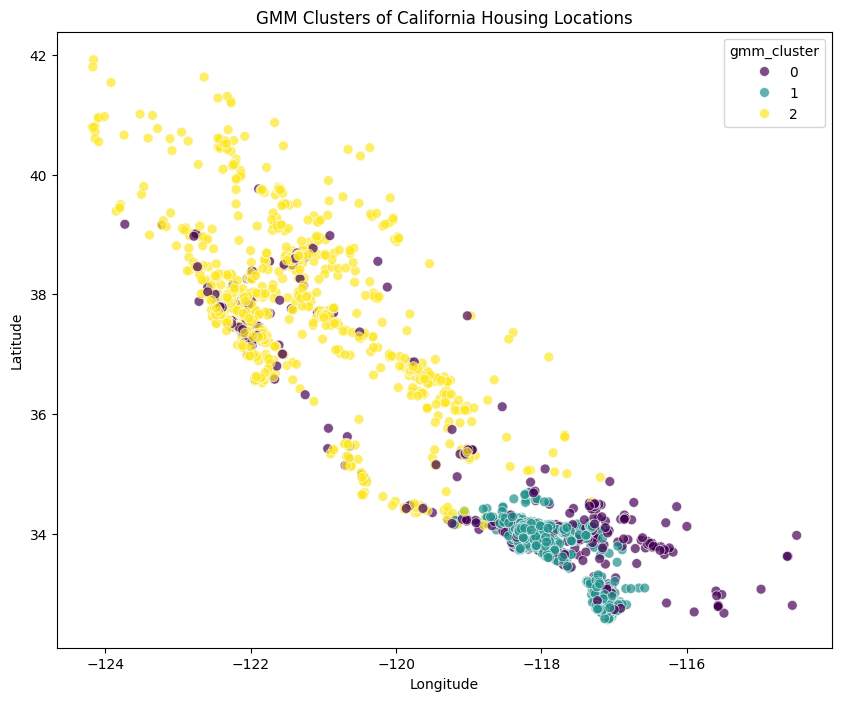

In [139]:
from sklearn.mixture import GaussianMixture

# We will use the scaled data (X_scaled) for GMMs, as it's often beneficial for distance-based algorithms.

# Initialize GMM model
# Let's start by assuming 3 components (clusters), similar to K-Means and Hierarchical Clustering.
# We can experiment with 'covariance_type' (e.g., 'full', 'tied', 'diag', 'spherical')
gmm = GaussianMixture(n_components=3, random_state=42, covariance_type='full')

# Fit the model to the scaled data
gmm.fit(X_scaled)

# Get the cluster labels (the component with the highest probability for each point)
gmm_cluster_labels = gmm.predict(X_scaled)

# Add the cluster labels to our DataFrame
df['gmm_cluster'] = gmm_cluster_labels

print("Gaussian Mixture Model clustering performed successfully!")
print("First 5 rows with GMM cluster labels:")
display(df.head())

# Analyze cluster characteristics
gmm_cluster_summary = df.groupby('gmm_cluster')[X.columns].mean()
print("\nGMM Cluster Summary (Mean of Features per Cluster):")
display(gmm_cluster_summary)

# Visualize the clusters using latitude and longitude
plt.figure(figsize=(10, 8))
sns.scatterplot(x='longitude', y='latitude', hue='gmm_cluster', data=df, palette='viridis', s=50, alpha=0.7)
plt.title('GMM Clusters of California Housing Locations')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

### Anomaly Detection using Isolation Forest

Anomaly Detection is the process of identifying data points, events, or observations that do not conform to an expected pattern or other items in a dataset. These anomalies often signify some critical or unusual phenomenon.

**Isolation Forest** is an ensemble learning method specifically designed for anomaly detection. It builds an ensemble of decision trees (Isolation Trees) where each tree isolates anomalies by randomly selecting a feature and then randomly selecting a split value between the maximum and minimum values of the selected feature. This random partitioning continues until the anomaly is isolated. Anomalies are points that require fewer splits to be isolated compared to normal points.

Key parameters:
- `n_estimators`: The number of base estimators (trees) in the ensemble.
- `contamination`: The proportion of outliers in the dataset. This is used when fitting to define the threshold on the scores of the samples.
- `random_state`: For reproducibility.

Isolation Forest anomaly detection performed successfully!
First 5 rows with anomaly labels and scores:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,cluster,hierarchical_cluster,dbscan_cluster,gmm_cluster,anomaly_label_if,anomaly_score_if
0,-122.05,37.37,27.0,3885.0,661.0,1537.0,606.0,6.6085,344700.0,0,1,-1,2,1,0.155736
1,-118.30,34.26,43.0,1510.0,310.0,809.0,277.0,3.5990,176500.0,1,0,0,1,1,0.222355
2,-117.81,33.78,27.0,3589.0,507.0,1484.0,495.0,5.7934,270500.0,0,0,0,1,1,0.204891
3,-118.36,33.82,28.0,67.0,15.0,49.0,11.0,6.1359,330000.0,1,0,-1,1,1,0.128095
4,-119.67,36.33,19.0,1241.0,244.0,850.0,237.0,2.9375,81700.0,1,0,-1,2,1,0.195947



Number of anomalies detected: 30

Summary statistics for anomaly scores:


,anomaly_score_if
count,3000.000000
mean,0.171365
std,0.051325
min,-0.079753
25%,0.147535
50%,0.181717
75%,0.206960
max,0.244028


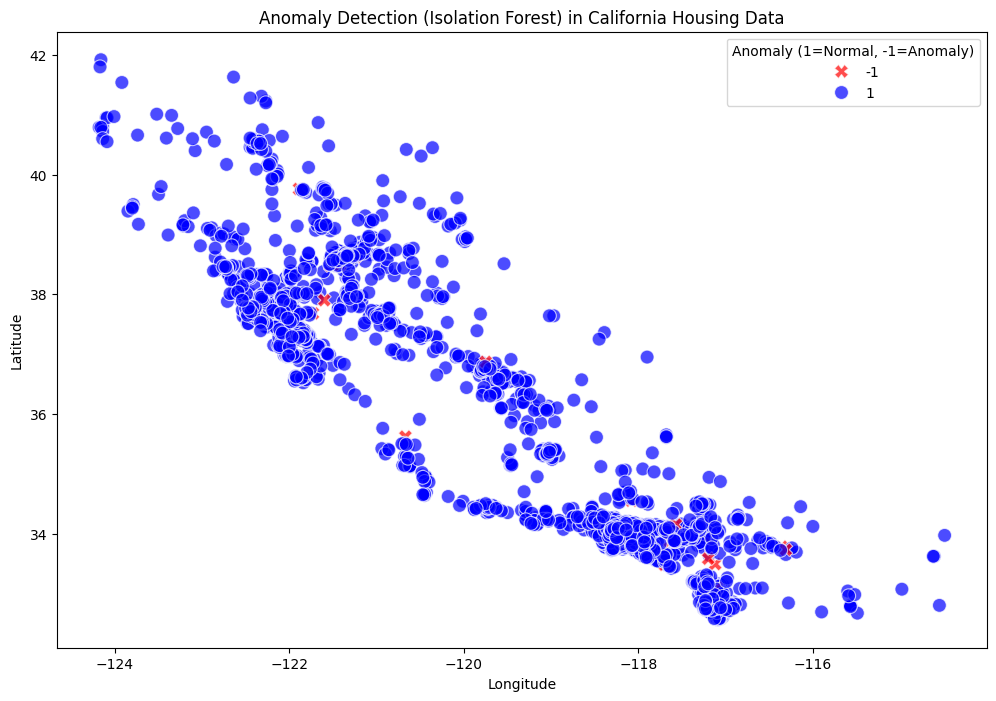


Characteristics of identified anomalies (first 5 rows):


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,cluster,hierarchical_cluster,dbscan_cluster,gmm_cluster,anomaly_label_if,anomaly_score_if
33,-118.08,34.55,5.0,16181.0,2971.0,8152.0,2651.0,4.5237,141800.0,2,2,-1,0,-1,-0.032618
292,-116.36,33.78,6.0,24121.0,4522.0,4176.0,2221.0,3.3799,239300.0,2,2,-1,0,-1,-0.064400
321,-121.73,37.68,17.0,20354.0,3493.0,8768.0,3293.0,5.4496,238900.0,2,2,-1,0,-1,-0.043202
405,-120.67,35.62,6.0,12779.0,2441.0,6085.0,2157.0,3.8661,168100.0,2,2,-1,0,-1,-0.036721
555,-118.45,34.12,20.0,10722.0,1617.0,3731.0,1511.0,9.7449,500001.0,2,0,-1,0,-1,-0.013744


In [140]:
from sklearn.ensemble import IsolationForest

# We will use the original features (X) for anomaly detection.
# Scaling might not be as critical for Isolation Forest as it is for distance-based methods,
# but it generally doesn't hurt.

# Initialize Isolation Forest model
# 'n_estimators' is the number of trees.
# 'contamination' is the expected proportion of outliers in the data, a crucial parameter.
# If not known, a reasonable guess (e.g., 0.01 for 1%) can be a starting point.
isolation_forest = IsolationForest(n_estimators=100, contamination=0.01, random_state=42, n_jobs=-1)

# Fit the model to the data
# No need for separate train/test split as it's unsupervised. The model learns from the entire dataset.
isolation_forest.fit(X)

# Predict anomalies (-1 for outliers, 1 for inliers)
df['anomaly_label_if'] = isolation_forest.predict(X)

# Get the anomaly scores (lower score indicates higher anomaly)
df['anomaly_score_if'] = isolation_forest.decision_function(X)

print("Isolation Forest anomaly detection performed successfully!")
print("First 5 rows with anomaly labels and scores:")
display(df.head())

# Count the number of anomalies identified
anomalies_count = df[df['anomaly_label_if'] == -1].shape[0]
print(f"\nNumber of anomalies detected: {anomalies_count}")

# Display summary statistics for anomaly scores
print("\nSummary statistics for anomaly scores:")
display(df['anomaly_score_if'].describe())

# Visualize anomalies
plt.figure(figsize=(12, 8))
sns.scatterplot(x='longitude', y='latitude', hue='anomaly_label_if', data=df,
                palette={1: 'blue', -1: 'red'}, style='anomaly_label_if', markers={1: 'o', -1: 'X'}, s=100, alpha=0.7)
plt.title('Anomaly Detection (Isolation Forest) in California Housing Data')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(title='Anomaly (1=Normal, -1=Anomaly)')
plt.show()

# You can also investigate the features of the identified anomalies
print("\nCharacteristics of identified anomalies (first 5 rows):")
display(df[df['anomaly_label_if'] == -1].head())

### Recurrent Neural Network (RNN)

Recurrent Neural Networks (RNNs) are a class of neural networks designed for sequential data. Unlike traditional feedforward networks, RNNs have loops that allow information to persist from one step of the sequence to the next, making them ideal for tasks like natural language processing, speech recognition, and time-series forecasting.

We will implement a simple RNN for **sentiment analysis** using the **IMDB movie review dataset**. The goal is to classify movie reviews as either positive or negative.

In [162]:
import tensorflow as tf
from tensorflow import keras
from keras.datasets import imdb
from keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

# Load the IMDB dataset
# num_words: The maximum number of words to keep, based on word frequency.
(X_train_imdb, y_train_imdb), (X_test_imdb, y_test_imdb) = imdb.load_data(num_words=10000)

# Pad sequences to ensure all reviews have the same length
# maxlen: Maximum length of all sequences.
# padding: 'pre' or 'post' padding.
maxlen = 250 # We'll cap reviews at 250 words
X_train_rnn = pad_sequences(X_train_imdb, maxlen=maxlen, padding='post')
X_test_rnn = pad_sequences(X_test_imdb, maxlen=maxlen, padding='post')

print(f"Shape of X_train for RNN: {X_train_rnn.shape}")
print(f"Shape of y_train for RNN: {y_train_imdb.shape}")
print(f"Shape of X_test for RNN: {X_test_rnn.shape}")
print(f"Shape of y_test for RNN: {y_test_imdb.shape}")

# Display an example review (first 10 words) and its sentiment
# To decode, we would typically get the word_index and invert it.
# For now, just show the numerical representation.
print(f"\nExample training review (first 10 words, numerical): {X_train_rnn[0][:10]}")
print(f"Example training review sentiment (0=negative, 1=positive): {y_train_imdb[0]}")

Shape of X_train for RNN: (25000, 250)
Shape of y_train for RNN: (25000,)
Shape of X_test for RNN: (25000, 250)
Shape of y_test for RNN: (25000,)

Example training review (first 10 words, numerical): [   1   14   22   16   43  530  973 1622 1385   65]
Example training review sentiment (0=negative, 1=positive): 1


In [163]:
# Build a simple RNN model
vocabulary_size = 10000 # Same as num_words when loading data
embedding_dim = 32    # Dimension of the word embeddings

model_rnn = keras.Sequential([
    keras.layers.Embedding(vocabulary_size, embedding_dim, input_length=maxlen), # Embedding layer
    keras.layers.SimpleRNN(32), # SimpleRNN layer with 32 units
    keras.layers.Dense(1, activation='sigmoid') # Output layer for binary classification
])

# Compile the model
model_rnn.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

model_rnn.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [164]:
# Train the model
history_rnn = model_rnn.fit(X_train_rnn, y_train_imdb, epochs=5, batch_size=64, validation_split=0.2, verbose=1)

print("\nRNN model trained successfully!")

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 26s 75ms/step - accuracy: 0.5112 - loss: 0.6908 - val_accuracy: 0.5446 - val_loss: 0.6828
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 22s 69ms/step - accuracy: 0.6028 - loss: 0.6420 - val_accuracy: 0.5396 - val_loss: 0.6831
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 23s 75ms/step - accuracy: 0.6296 - loss: 0.5877 - val_accuracy: 0.5372 - val_loss: 0.7009
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 40s 72ms/step - accuracy: 0.6560 - loss: 0.5306 - val_accuracy: 0.5206 - val_loss: 0.6898
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 23s 75ms/step - accuracy: 0.6750 - loss: 0.5049 - val_accuracy: 0.5240 - val_loss: 0.7788

RNN model trained successfully!


In [165]:
# Evaluate the model on the test set
loss_rnn, accuracy_rnn = model_rnn.evaluate(X_test_rnn, y_test_imdb, verbose=0)
print(f"\nRNN Model Loss on IMDB test set: {loss_rnn:.4f}")
print(f"RNN Model Accuracy on IMDB test set: {accuracy_rnn:.4f}")

# Make predictions
y_pred_rnn_probs = model_rnn.predict(X_test_rnn)
y_pred_rnn = (y_pred_rnn_probs > 0.5).astype("int32") # Convert probabilities to binary class (0 or 1)

print("\nClassification Report:")
print(classification_report(y_test_imdb, y_pred_rnn, target_names=['negative', 'positive']))


RNN Model Loss on IMDB test set: 0.7815
RNN Model Accuracy on IMDB test set: 0.5166
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step

Classification Report:
              precision    recall  f1-score   support

    negative       0.51      0.69      0.59     12500
    positive       0.53      0.35      0.42     12500

    accuracy                           0.52     25000
   macro avg       0.52      0.52      0.50     25000
weighted avg       0.52      0.52      0.50     25000



### Long Short-Term Memory (LSTM)

**Long Short-Term Memory (LSTM)** networks are a special kind of Recurrent Neural Network (RNN) capable of learning long-term dependencies. They were introduced to address the vanishing gradient problem that standard RNNs can suffer from, allowing them to remember information for extended periods.

LSTMs are particularly well-suited for processing, predicting, and classifying sequential data, such as time series, speech, and natural language. They achieve this through a unique internal structure called 'cells', which contain several 'gates' (forget, input, and output gates) that control the flow of information.

We will implement an LSTM model for **sentiment analysis** using the **IMDB movie review dataset**, similar to the simple RNN. This will allow us to compare the performance of LSTMs against simpler RNNs on this sequence classification task.

In [166]:
import tensorflow as tf
from tensorflow import keras
from keras.datasets import imdb
from keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

# Reuse the IMDB dataset loading and preprocessing from the RNN section
# (X_train_imdb, y_train_imdb), (X_test_imdb, y_test_imdb) = imdb.load_data(num_words=10000)
# maxlen = 250
# X_train_rnn = pad_sequences(X_train_imdb, maxlen=maxlen, padding='post')
# X_test_rnn = pad_sequences(X_test_imdb, maxlen=maxlen, padding='post')

print(f"Reusing preprocessed data from RNN for LSTM model.")
print(f"Shape of X_train for LSTM: {X_train_rnn.shape}")
print(f"Shape of y_train for LSTM: {y_train_imdb.shape}")
print(f"Shape of X_test for LSTM: {X_test_rnn.shape}")
print(f"Shape of y_test for LSTM: {y_test_imdb.shape}")

Reusing preprocessed data from RNN for LSTM model.
Shape of X_train for LSTM: (25000, 250)
Shape of y_train for LSTM: (25000,)
Shape of X_test for LSTM: (25000, 250)
Shape of y_test for LSTM: (25000,)


In [170]:
# Build an LSTM model
vocabulary_size = 10000 # Same as num_words when loading data
embedding_dim = 32    # Dimension of the word embeddings (can be adjusted)

model_lstm = keras.Sequential([
    keras.layers.Embedding(vocabulary_size, embedding_dim), # Embedding layer
    keras.layers.LSTM(32), # LSTM layer with 32 units
    keras.layers.Dense(1, activation='sigmoid') # Output layer for binary classification
])

# Compile the model
model_lstm.compile(optimizer='adam',
                   loss='binary_crossentropy',
                   metrics=['accuracy'])

model_lstm.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [168]:
# Train the LSTM model
history_lstm = model_lstm.fit(X_train_rnn, y_train_imdb, epochs=5, batch_size=64, validation_split=0.2, verbose=1)

print("\nLSTM model trained successfully!")

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 44s 132ms/step - accuracy: 0.5332 - loss: 0.6905 - val_accuracy: 0.5402 - val_loss: 0.6841
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 86s 145ms/step - accuracy: 0.5768 - loss: 0.6509 - val_accuracy: 0.5960 - val_loss: 0.6255
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 132ms/step - accuracy: 0.6125 - loss: 0.5874 - val_accuracy: 0.6026 - val_loss: 0.6124
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 131ms/step - accuracy: 0.6536 - loss: 0.5354 - val_accuracy: 0.7786 - val_loss: 0.5122
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 132ms/step - accuracy: 0.8452 - loss: 0.4018 - val_accuracy: 0.8230 - val_loss: 0.4527

LSTM model trained successfully!


In [169]:
# Evaluate the LSTM model on the test set
loss_lstm, accuracy_lstm = model_lstm.evaluate(X_test_rnn, y_test_imdb, verbose=0)
print(f"\nLSTM Model Loss on IMDB test set: {loss_lstm:.4f}")
print(f"LSTM Model Accuracy on IMDB test set: {accuracy_lstm:.4f}")

# Make predictions
y_pred_lstm_probs = model_lstm.predict(X_test_rnn)
y_pred_lstm = (y_pred_lstm_probs > 0.5).astype("int32") # Convert probabilities to binary class (0 or 1)

print("\nClassification Report:")
print(classification_report(y_test_imdb, y_pred_lstm, target_names=['negative', 'positive']))


LSTM Model Loss on IMDB test set: 0.4662
LSTM Model Accuracy on IMDB test set: 0.8139
782/782 ━━━━━━━━━━━━━━━━━━━━ 21s 26ms/step

Classification Report:
              precision    recall  f1-score   support

    negative       0.79      0.85      0.82     12500
    positive       0.84      0.78      0.81     12500

    accuracy                           0.81     25000
   macro avg       0.82      0.81      0.81     25000
weighted avg       0.82      0.81      0.81     25000



### Cross-Validation

**Cross-validation** is a resampling procedure used to evaluate machine learning models on a limited data sample. The procedure has a single parameter called `k` that refers to the number of groups that a given data sample is to be split into. It is often called k-fold cross-validation.

When a `k` value is chosen, the data is split into `k` folds. The model is trained on `k-1` folds, and the remaining fold is used as the test set. This process is repeated `k` times, with each fold used exactly once as the test set. The results from each fold are then averaged to produce a single estimation of the model's performance.

This method helps in getting a more reliable estimate of model performance and ensures that the model is not overfitting to a particular train-test split.

In [141]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import load_iris

# Load the Iris dataset
iris = load_iris()
X_iris, y_iris = iris.data, iris.target

# Initialize a Logistic Regression model
log_reg_cv = LogisticRegression(random_state=42, solver='liblinear') # Using 'liblinear' solver for binary classification

# Perform 5-fold cross-validation
# 'scoring' can be changed to 'accuracy', 'precision', 'recall', 'f1', etc.
scores = cross_val_score(log_reg_cv, X_iris, y_iris, cv=5, scoring='accuracy')

print(f"Cross-validation scores: {scores}")
print(f"Mean accuracy: {scores.mean():.4f}")
print(f"Standard deviation of accuracy: {scores.std():.4f}")

Cross-validation scores: [1.         0.96666667 0.93333333 0.9        1.        ]
Mean accuracy: 0.9600
Standard deviation of accuracy: 0.0389


### Hyperparameter Tuning

**Hyperparameter tuning** (or optimization) is the process of finding the right combination of hyperparameters that maximizes the model's performance on a given dataset. Hyperparameters are parameters whose values are set before the learning process begins (e.g., `n_estimators` in RandomForest, `C` and `gamma` in SVMs, `learning_rate` in XGBoost).

There are several strategies for hyperparameter tuning:
1.  **Grid Search:** Exhaustively searches through a specified subset of hyperparameter combinations.
2.  **Random Search:** Randomly samples hyperparameters from a given distribution for a fixed number of iterations.
3.  **Bayesian Optimization:** Uses a probabilistic model to select promising hyperparameters to evaluate in an intelligent way.

We will demonstrate **Grid Search** as it's a common and straightforward method.

In [142]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.datasets import load_iris

# Load the Iris dataset
iris = load_iris()
X_iris, y_iris = iris.data, iris.target

# Define the parameter grid to search
# For SVC, common parameters are 'C' (regularization parameter) and 'kernel'.
param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf']
}

# Initialize an SVC model
svc_grid = SVC(random_state=42)

# Initialize GridSearchCV
# cv=5 for 5-fold cross-validation during the search
# verbose=1 for output during the search
grid_search = GridSearchCV(svc_grid, param_grid, cv=5, verbose=1, n_jobs=-1)

# Fit GridSearchCV to the data
grid_search.fit(X_iris, y_iris)

print("Grid Search completed!")

# Best parameters found
print(f"Best parameters: {grid_search.best_params_}")

# Best cross-validation score achieved with the best parameters
print(f"Best cross-validation accuracy: {grid_search.best_score_:.4f}")

# You can also get the best estimator (model) directly
best_svc_model = grid_search.best_estimator_
print("\nBest SVC model trained with optimal hyperparameters:")
print(best_svc_model)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Grid Search completed!
Best parameters: {'C': 1, 'kernel': 'linear'}
Best cross-validation accuracy: 0.9800

Best SVC model trained with optimal hyperparameters:
SVC(C=1, kernel='linear', random_state=42)


### K-Nearest Neighbors (KNN) Classifier

As discussed, K-Nearest Neighbors (KNN) is a supervised learning algorithm that can be used for both classification and regression tasks. It's a non-parametric, instance-based learning algorithm that classifies new data points based on the majority class among their 'k' nearest neighbors in the feature space.

**Key concepts:**
*   **k:** The number of nearest neighbors to consider. Choosing an optimal `k` is crucial and often determined through cross-validation or hyperparameter tuning.
*   **Distance Metric:** How the 'closeness' between data points is measured (e.g., Euclidean distance, Manhattan distance).

Let's apply KNN to the Iris dataset for classification.

In [143]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler

# Load the Iris dataset
iris = load_iris()
X_knn, y_knn = iris.data, iris.target

# It's highly recommended to scale the data for KNN because it relies on distance metrics.
scaler_knn = StandardScaler()
X_knn_scaled = scaler_knn.fit_transform(X_knn)

# Split the dataset into training and testing sets
X_train_knn, X_test_knn, y_train_knn, y_test_knn = train_test_split(
    X_knn_scaled, y_knn, test_size=0.3, random_state=42, stratify=y_knn # stratify ensures balanced classes in splits
)

print(f"Shape of X_train for KNN Classification: {X_train_knn.shape}")
print(f"Shape of y_train for KNN Classification: {y_train_knn.shape}")

# Initialize the K-Nearest Neighbors Classifier model
# Let's start with k=5 (n_neighbors=5)
knn_classifier = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_classifier.fit(X_train_knn, y_train_knn)

print("K-Nearest Neighbors Classifier model trained successfully!")

# Make predictions on the test set
y_pred_knn = knn_classifier.predict(X_test_knn)

# Evaluate the model
accuracy_knn = accuracy_score(y_test_knn, y_pred_knn)

print(f"\nK-Nearest Neighbors Classifier Accuracy on Iris: {accuracy_knn:.4f}")
print("\nClassification Report:")
print(classification_report(y_test_knn, y_pred_knn, target_names=iris.target_names))


Shape of X_train for KNN Classification: (105, 4)
Shape of y_train for KNN Classification: (105,)
K-Nearest Neighbors Classifier model trained successfully!

K-Nearest Neighbors Classifier Accuracy on Iris: 0.9111

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.79      1.00      0.88        15
   virginica       1.00      0.73      0.85        15

    accuracy                           0.91        45
   macro avg       0.93      0.91      0.91        45
weighted avg       0.93      0.91      0.91        45



### Finding the Optimal `k` for KNN

The choice of `k` is critical for KNN performance. We can use cross-validation and hyperparameter tuning (like Grid Search) to find the best `k`.

Let's use `GridSearchCV` to find the optimal `n_neighbors` for our KNN classifier on the Iris dataset.

In [144]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

# Define a range of k values to search
param_grid_knn = {
    'n_neighbors': list(range(1, 31)) # Search k from 1 to 30
}

# Initialize a KNN classifier
knn_base = KNeighborsClassifier()

# Initialize GridSearchCV
grid_search_knn = GridSearchCV(knn_base, param_grid_knn, cv=10, verbose=1, n_jobs=-1, scoring='accuracy')

# Fit GridSearchCV to the scaled training data
grid_search_knn.fit(X_train_knn, y_train_knn)

print("Grid Search for optimal k completed!")

# Best parameters found
print(f"Best parameters for KNN: {grid_search_knn.best_params_}")

# Best cross-validation score achieved with the best parameters
print(f"Best cross-validation accuracy for KNN: {grid_search_knn.best_score_:.4f}")

# Evaluate the best KNN model on the test set
best_knn_model = grid_search_knn.best_estimator_
y_pred_best_knn = best_knn_model.predict(X_test_knn)
accuracy_best_knn = accuracy_score(y_test_knn, y_pred_best_knn)

print(f"\nAccuracy of best KNN model on test set: {accuracy_best_knn:.4f}")
print("\nClassification Report for best KNN model:")
print(classification_report(y_test_knn, y_pred_best_knn, target_names=iris.target_names))


Fitting 10 folds for each of 30 candidates, totalling 300 fits
Grid Search for optimal k completed!
Best parameters for KNN: {'n_neighbors': 9}
Best cross-validation accuracy for KNN: 0.9718

Accuracy of best KNN model on test set: 0.9556

Classification Report for best KNN model:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.88      1.00      0.94        15
   virginica       1.00      0.87      0.93        15

    accuracy                           0.96        45
   macro avg       0.96      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



### K-Nearest Neighbors (KNN) Regressor

KNN Regressor works on the principle that the value of a new data point can be predicted by taking the average of the target values of its 'k' nearest neighbors in the training set.

We will apply KNN Regressor to the California Housing dataset, predicting `median_house_value` using the same features (`X`) we used for other regression models. Remember, scaling the features is particularly important for distance-based algorithms like KNN.

In [145]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# We will use the features (X) and target (y) from the California housing dataset

# Scale the features (X) – crucial for distance-based algorithms like KNN
scaler_knn_reg = StandardScaler()
X_scaled_knn_reg = scaler_knn_reg.fit_transform(X)

# Split the scaled data into training and testing sets
X_train_knn_reg, X_test_knn_reg, y_train_knn_reg, y_test_knn_reg = train_test_split(
    X_scaled_knn_reg, y, test_size=0.2, random_state=42
)

print(f"Shape of X_train for KNN Regression: {X_train_knn_reg.shape}")
print(f"Shape of y_train for KNN Regression: {y_train_knn_reg.shape}")

# Initialize the K-Nearest Neighbors Regressor model
# Let's start with n_neighbors=5
knn_regressor = KNeighborsRegressor(n_neighbors=5, n_jobs=-1)

# Train the model
knn_regressor.fit(X_train_knn_reg, y_train_knn_reg)

print("K-Nearest Neighbors Regressor model trained successfully!")

# Make predictions on the test set
y_pred_knn_reg = knn_regressor.predict(X_test_knn_reg)

# Evaluate the model
mse_knn_reg = mean_squared_error(y_test_knn_reg, y_pred_knn_reg)
rmse_knn_reg = np.sqrt(mse_knn_reg)
r2_knn_reg = r2_score(y_test_knn_reg, y_pred_knn_reg)

print(f"\nK-Nearest Neighbors Regressor Mean Squared Error: {mse_knn_reg:.2f}")
print(f"K-Nearest Neighbors Regressor Root Mean Squared Error: {rmse_knn_reg:.2f}")
print(f"K-Nearest Neighbors Regressor R-squared: {r2_knn_reg:.4f}")

Shape of X_train for KNN Regression: (2400, 6)
Shape of y_train for KNN Regression: (2400,)
K-Nearest Neighbors Regressor model trained successfully!

K-Nearest Neighbors Regressor Mean Squared Error: 5112217836.60
K-Nearest Neighbors Regressor Root Mean Squared Error: 71499.78
K-Nearest Neighbors Regressor R-squared: 0.5941


### Naive Bayes Classifier

**Naive Bayes** is a family of simple probabilistic classifiers based on applying Bayes' theorem with strong (naive) independence assumptions between the features. They are known for their simplicity, speed, and efficiency, especially on large datasets.

We'll use the **Gaussian Naive Bayes** variant, which assumes that the likelihood of the features is Gaussian. It's often a good baseline model for classification tasks.

We will apply it to the Iris dataset for classification.

In [147]:
from sklearn.naive_bayes import GaussianNB
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

# Load the Iris dataset
iris = load_iris()
X_nb, y_nb = iris.data, iris.target

# Split the dataset into training and testing sets
X_train_nb, X_test_nb, y_train_nb, y_test_nb = train_test_split(
    X_nb, y_nb, test_size=0.3, random_state=42, stratify=y_nb # stratify ensures balanced classes in splits
)

print(f"Shape of X_train for Naive Bayes Classification: {X_train_nb.shape}")
print(f"Shape of y_train for Naive Bayes Classification: {y_train_nb.shape}")

# Initialize the Gaussian Naive Bayes model
gnb_model = GaussianNB()

# Train the model
gnb_model.fit(X_train_nb, y_train_nb)

print("Gaussian Naive Bayes Classifier model trained successfully!")

# Make predictions on the test set
y_pred_nb = gnb_model.predict(X_test_nb)

# Evaluate the model
accuracy_nb = accuracy_score(y_test_nb, y_pred_nb)

print(f"\nGaussian Naive Bayes Classifier Accuracy on Iris: {accuracy_nb:.4f}")
print("\nClassification Report:")
print(classification_report(y_test_nb, y_pred_nb, target_names=iris.target_names))

Shape of X_train for Naive Bayes Classification: (105, 4)
Shape of y_train for Naive Bayes Classification: (105,)
Gaussian Naive Bayes Classifier model trained successfully!

Gaussian Naive Bayes Classifier Accuracy on Iris: 0.9111

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



### LightGBM Regressor

**LightGBM (Light Gradient Boosting Machine)** is an advanced gradient boosting framework that uses tree-based learning algorithms. It's designed for high speed and efficiency, especially on large datasets, and is known for its high accuracy. It's similar in principle to XGBoost but often faster.

We'll apply **LightGBM Regressor** to the California Housing dataset to predict `median_house_value`, reusing the scaled features (`X_scaled_knn_reg`) and target (`y`) from the previous regression tasks.

In [148]:
import lightgbm as lgb
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# We will reuse the scaled data splits from KNN Regressor section for consistency
# X_train_knn_reg, X_test_knn_reg, y_train_knn_reg, y_test_knn_reg

print(f"Shape of X_train for LightGBM Regression: {X_train_knn_reg.shape}")
print(f"Shape of y_train for LightGBM Regression: {y_train_knn_reg.shape}")

# Initialize the LightGBM Regressor model
lgbm_reg_model = lgb.LGBMRegressor(
    objective='regression', # For regression tasks
    n_estimators=100,      # Number of boosting rounds
    learning_rate=0.1,     # Step size shrinkage
    random_state=42,       # For reproducibility
    n_jobs=-1              # Use all available cores
)

# Train the model
lgbm_reg_model.fit(X_train_knn_reg, y_train_knn_reg)

print("LightGBM Regressor model trained successfully!")

# Make predictions on the test set
y_pred_lgbm_reg = lgbm_reg_model.predict(X_test_knn_reg)

# Evaluate the model
mse_lgbm_reg = mean_squared_error(y_test_knn_reg, y_pred_lgbm_reg)
rmse_lgbm_reg = np.sqrt(mse_lgbm_reg)
r2_lgbm_reg = r2_score(y_test_knn_reg, y_pred_lgbm_reg)

print(f"\nLightGBM Regressor Mean Squared Error: {mse_lgbm_reg:.2f}")
print(f"LightGBM Regressor Root Mean Squared Error: {rmse_lgbm_reg:.2f}")
print(f"LightGBM Regressor R-squared: {r2_lgbm_reg:.4f}")

Shape of X_train for LightGBM Regression: (2400, 6)
Shape of y_train for LightGBM Regression: (2400,)
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000595 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1327
[LightGBM] [Info] Number of data points in the train set: 2400, number of used features: 6
[LightGBM] [Info] Start training from score 207293.292917
LightGBM Regressor model trained successfully!

LightGBM Regressor Mean Squared Error: 3077058825.26
LightGBM Regressor Root Mean Squared Error: 55471.24
LightGBM Regressor R-squared: 0.7557


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


### AdaBoost Regressor

**AdaBoost (Adaptive Boosting)** is an ensemble learning algorithm that works by combining multiple "weak" learners (typically simple decision trees, known as stumps) to create a strong learner. It sequentially trains models, giving more weight to misclassified samples (or samples with high errors in regression) in subsequent iterations.

We will apply **AdaBoost Regressor** to the California Housing dataset to predict `median_house_value`, reusing the scaled features (`X_scaled_knn_reg`) and target (`y`) from the previous regression tasks. We will use a `DecisionTreeRegressor` as the base estimator.

In [149]:
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# We will reuse the scaled data splits from KNN Regressor section for consistency
# X_train_knn_reg, X_test_knn_reg, y_train_knn_reg, y_test_knn_reg

print(f"Shape of X_train for AdaBoost Regression: {X_train_knn_reg.shape}")
print(f"Shape of y_train for AdaBoost Regression: {y_train_knn_reg.shape}")

# Initialize a base estimator (e.g., a shallow Decision Tree)
# max_depth=4 is a common choice for a weak learner in boosting
base_estimator = DecisionTreeRegressor(max_depth=4, random_state=42)

# Initialize the AdaBoost Regressor model
adaboost_reg_model = AdaBoostRegressor(
    estimator=base_estimator,
    n_estimators=100,      # Number of boosting rounds
    learning_rate=0.1,     # Contribution of each base estimator
    random_state=42        # For reproducibility
)

# Train the model
adaboost_reg_model.fit(X_train_knn_reg, y_train_knn_reg)

print("AdaBoost Regressor model trained successfully!")

# Make predictions on the test set
y_pred_adaboost_reg = adaboost_reg_model.predict(X_test_knn_reg)

# Evaluate the model
mse_adaboost_reg = mean_squared_error(y_test_knn_reg, y_pred_adaboost_reg)
rmse_adaboost_reg = np.sqrt(mse_adaboost_reg)
r2_adaboost_reg = r2_score(y_test_knn_reg, y_pred_adaboost_reg)

print(f"\nAdaBoost Regressor Mean Squared Error: {mse_adaboost_reg:.2f}")
print(f"AdaBoost Regressor Root Mean Squared Error: {rmse_adaboost_reg:.2f}")
print(f"AdaBoost Regressor R-squared: {r2_adaboost_reg:.4f}")

Shape of X_train for AdaBoost Regression: (2400, 6)
Shape of y_train for AdaBoost Regression: (2400,)
AdaBoost Regressor model trained successfully!

AdaBoost Regressor Mean Squared Error: 5753700481.77
AdaBoost Regressor Root Mean Squared Error: 75853.15
AdaBoost Regressor R-squared: 0.5431


###DEEP LEARNING


### Perceptron

The Perceptron is the simplest type of artificial neural network and is a linear classifier. It makes predictions by computing a linear combination of its inputs and applying a step activation function. It's often used for binary classification tasks.

We'll use the Iris dataset, specifically a binary classification scenario (e.g., classifying Setosa vs. Versicolor), to demonstrate the Perceptron.

In [150]:
from sklearn.linear_model import Perceptron
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler

# Load the Iris dataset
iris = load_iris()
X_iris_perc, y_iris_perc = iris.data, iris.target

# For Perceptron, we'll focus on a binary classification problem for simplicity.
# Let's take two classes, e.g., Setosa (0) and Versicolor (1).
# We'll filter the data to include only these two classes.
binary_class_indices = (y_iris_perc == 0) | (y_iris_perc == 1)
X_binary_perc = X_iris_perc[binary_class_indices]
y_binary_perc = y_iris_perc[binary_class_indices]

# Scale the features – Perceptron is sensitive to feature scaling.
scaler_perc = StandardScaler()
X_binary_perc_scaled = scaler_perc.fit_transform(X_binary_perc)

# Split the dataset into training and testing sets
X_train_perc, X_test_perc, y_train_perc, y_test_perc = train_test_split(
    X_binary_perc_scaled, y_binary_perc, test_size=0.3, random_state=42, stratify=y_binary_perc
)

print(f"Shape of X_train for Perceptron: {X_train_perc.shape}")
print(f"Shape of y_train for Perceptron: {y_train_perc.shape}")

# Initialize the Perceptron model
# tol: The stopping criterion. The algorithm will stop when the loss is not improving by at least tol.
# random_state: For reproducibility.
perc_model = Perceptron(tol=1e-3, random_state=42)

# Train the model
perc_model.fit(X_train_perc, y_train_perc)

print("\nPerceptron model trained successfully!")

# Make predictions on the test set
y_pred_perc = perc_model.predict(X_test_perc)

# Evaluate the model
accuracy_perc = accuracy_score(y_test_perc, y_pred_perc)

print(f"\nPerceptron Accuracy on Iris (binary): {accuracy_perc:.4f}")
print("\nClassification Report:")
# Filter target names for the binary classification case
binary_target_names = [name for i, name in enumerate(iris.target_names) if i < 2]
print(classification_report(y_test_perc, y_pred_perc, target_names=binary_target_names))

Shape of X_train for Perceptron: (70, 4)
Shape of y_train for Perceptron: (70,)

Perceptron model trained successfully!

Perceptron Accuracy on Iris (binary): 1.0000

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      1.00      1.00        15

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



### Convolutional Neural Network (CNN)

A Convolutional Neural Network (CNN) is a class of deep neural networks, most commonly applied to analyze visual imagery. They are particularly good at identifying patterns in images, which makes them highly effective for tasks like image classification, object detection, and image segmentation. The key innovation of CNNs lies in their use of convolutional layers, which apply learnable filters to input data, and pooling layers, which reduce dimensionality.

We will implement a simple CNN for image classification using the CIFAR-10 dataset. CIFAR-10 is a dataset of 60,000 32x32 color images in 10 classes, with 6,000 images per class. There are 50,000 training images and 10,000 test images.

In [152]:
import tensorflow as tf
from tensorflow import keras
from keras.datasets import cifar10
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# Load the CIFAR-10 dataset
(X_train_cnn_full, y_train_cnn_full), (X_test_cnn_full, y_test_cnn_full) = cifar10.load_data()

# Normalize pixel values to be between 0 and 1
X_train_cnn = X_train_cnn_full.astype('float32') / 255.0
X_test_cnn = X_test_cnn_full.astype('float32') / 255.0

# Convert class vectors to binary class matrices (one-hot encoding)
y_train_cnn = keras.utils.to_categorical(y_train_cnn_full, 10)
y_test_cnn = keras.utils.to_categorical(y_test_cnn_full, 10)

print(f"Shape of X_train for CNN: {X_train_cnn.shape}")
print(f"Shape of y_train for CNN: {y_train_cnn.shape}")
print(f"Shape of X_test for CNN: {X_test_cnn.shape}")
print(f"Shape of y_test for CNN: {y_test_cnn.shape}")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Shape of X_train for CNN: (50000, 32, 32, 3)
Shape of y_train for CNN: (50000, 10)
Shape of X_test for CNN: (10000, 32, 32, 3)
Shape of y_test for CNN: (10000, 10)


In [153]:
# Build a simple CNN model
model_cnn = keras.Sequential([
    keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation='relu'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation='relu'),
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(10, activation='softmax') # 10 classes for CIFAR-10
])

# Compile the model
model_cnn.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model_cnn.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

In [154]:
# Train the model
history_cnn = model_cnn.fit(X_train_cnn, y_train_cnn, epochs=10, batch_size=64, validation_split=0.2, verbose=1)

print("\nCNN model trained successfully!")

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 128ms/step - accuracy: 0.4082 - loss: 1.6125 - val_accuracy: 0.4982 - val_loss: 1.4123
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 68s 106ms/step - accuracy: 0.5547 - loss: 1.2456 - val_accuracy: 0.5871 - val_loss: 1.1674
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 73s 92ms/step - accuracy: 0.6117 - loss: 1.0961 - val_accuracy: 0.6167 - val_loss: 1.0817
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 58s 93ms/step - accuracy: 0.6442 - loss: 1.0081 - val_accuracy: 0.6325 - val_loss: 1.0539
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 56s 90ms/step - accuracy: 0.6718 - loss: 0.9312 - val_accuracy: 0.6586 - val_loss: 0.9690
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 59s 94ms/step - accuracy: 0.6938 - loss: 0.8673 - val_accuracy: 0.6839 - val_loss: 0.9090
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 56s 89ms/step - accuracy: 0.7167 - loss: 0.8111 - val_accuracy: 0.6893 - val_loss: 0.8924
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 57s 91ms/step - accuracy: 0.7346 - loss: 0.7622 

In [155]:
# Evaluate the model on the test set
loss_cnn, accuracy_cnn = model_cnn.evaluate(X_test_cnn, y_test_cnn, verbose=0)
print(f"\nCNN Model Loss on CIFAR-10 test set: {loss_cnn:.4f}")
print(f"CNN Model Accuracy on CIFAR-10 test set: {accuracy_cnn:.4f}")

# Make predictions
y_pred_cnn_probs = model_cnn.predict(X_test_cnn)
y_pred_cnn = np.argmax(y_pred_cnn_probs, axis=1)
y_test_cnn_labels = np.argmax(y_test_cnn, axis=1)

# Define CIFAR-10 class names
cifar10_class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer', '    dog', 'frog', 'horse', 'ship', 'truck'
]

print("\nClassification Report:")
print(classification_report(y_test_cnn_labels, y_pred_cnn, target_names=cifar10_class_names))


CNN Model Loss on CIFAR-10 test set: 0.9245
CNN Model Accuracy on CIFAR-10 test set: 0.6916
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step

Classification Report:
              precision    recall  f1-score   support

    airplane       0.77      0.71      0.74      1000
  automobile       0.86      0.75      0.81      1000
        bird       0.65      0.51      0.57      1000
         cat       0.53      0.47      0.50      1000
        deer       0.55      0.78      0.64      1000
         dog       0.57      0.66      0.61      1000
        frog       0.75      0.79      0.77      1000
       horse       0.68      0.76      0.72      1000
        ship       0.82      0.79      0.80      1000
       truck       0.84      0.70      0.76      1000

    accuracy                           0.69     10000
   macro avg       0.70      0.69      0.69     10000
weighted avg       0.70      0.69      0.69     10000



### Recurrent Neural Network (RNN)

Recurrent Neural Networks (RNNs) are a class of neural networks designed for sequential data. Unlike traditional feedforward networks, RNNs have loops that allow information to persist from one step of the sequence to the next, making them ideal for tasks like natural language processing, speech recognition, and time-series forecasting.

We will implement a simple RNN for **sentiment analysis** using the **IMDB movie review dataset**. The goal is to classify movie reviews as either positive or negative.

In [156]:
import tensorflow as tf
from tensorflow import keras
from keras.datasets import imdb
from keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

# Load the IMDB dataset
# num_words: The maximum number of words to keep, based on word frequency.
(X_train_imdb, y_train_imdb), (X_test_imdb, y_test_imdb) = imdb.load_data(num_words=10000)

# Pad sequences to ensure all reviews have the same length
# maxlen: Maximum length of all sequences.
# padding: 'pre' or 'post' padding.
maxlen = 250 # We'll cap reviews at 250 words
X_train_rnn = pad_sequences(X_train_imdb, maxlen=maxlen, padding='post')
X_test_rnn = pad_sequences(X_test_imdb, maxlen=maxlen, padding='post')

print(f"Shape of X_train for RNN: {X_train_rnn.shape}")
print(f"Shape of y_train for RNN: {y_train_imdb.shape}")
print(f"Shape of X_test for RNN: {X_test_rnn.shape}")
print(f"Shape of y_test for RNN: {y_test_imdb.shape}")

# Display an example review (first 10 words) and its sentiment
# To decode, we would typically get the word_index and invert it.
# For now, just show the numerical representation.
print(f"\nExample training review (first 10 words, numerical): {X_train_rnn[0][:10]}")
print(f"Example training review sentiment (0=negative, 1=positive): {y_train_imdb[0]}")

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Shape of X_train for RNN: (25000, 250)
Shape of y_train for RNN: (25000,)
Shape of X_test for RNN: (25000, 250)
Shape of y_test for RNN: (25000,)

Example training review (first 10 words, numerical): [   1   14   22   16   43  530  973 1622 1385   65]
Example training review sentiment (0=negative, 1=positive): 1


In [157]:
# Build a simple RNN model
vocabulary_size = 10000 # Same as num_words when loading data
embedding_dim = 32    # Dimension of the word embeddings

model_rnn = keras.Sequential([
    keras.layers.Embedding(vocabulary_size, embedding_dim, input_length=maxlen), # Embedding layer
    keras.layers.SimpleRNN(32), # SimpleRNN layer with 32 units
    keras.layers.Dense(1, activation='sigmoid') # Output layer for binary classification
])

# Compile the model
model_rnn.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

model_rnn.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [158]:
# Train the model
history_rnn = model_rnn.fit(X_train_rnn, y_train_imdb, epochs=5, batch_size=64, validation_split=0.2, verbose=1)

print("\nRNN model trained successfully!")

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 84ms/step - accuracy: 0.5150 - loss: 0.6913 - val_accuracy: 0.5226 - val_loss: 0.6856
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 22s 69ms/step - accuracy: 0.5940 - loss: 0.6436 - val_accuracy: 0.5184 - val_loss: 0.6925
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 23s 73ms/step - accuracy: 0.6455 - loss: 0.5450 - val_accuracy: 0.5220 - val_loss: 0.7571
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 23s 74ms/step - accuracy: 0.6674 - loss: 0.4888 - val_accuracy: 0.5272 - val_loss: 0.7964
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 22s 70ms/step - accuracy: 0.6870 - loss: 0.4687 - val_accuracy: 0.5196 - val_loss: 0.8573

RNN model trained successfully!


In [160]:
# Evaluate the model on the test set
loss_rnn, accuracy_rnn = model_rnn.evaluate(X_test_rnn, y_test_imdb, verbose=0)
print(f"\nRNN Model Loss on IMDB test set: {loss_rnn:.4f}")
print(f"RNN Model Accuracy on IMDB test set: {accuracy_rnn:.4f}")

# Make predictions
y_pred_rnn_probs = model_rnn.predict(X_test_rnn)
y_pred_rnn = (y_pred_rnn_probs > 0.5).astype("int32") # Convert probabilities to binary class (0 or 1)

print("\nClassification Report:")
print(classification_report(y_test_imdb, y_pred_rnn, target_names=['negative', 'positive']))


RNN Model Loss on IMDB test set: 0.8512
RNN Model Accuracy on IMDB test set: 0.5188
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step

Classification Report:
              precision    recall  f1-score   support

    negative       0.55      0.21      0.31     12500
    positive       0.51      0.83      0.63     12500

    accuracy                           0.52     25000
   macro avg       0.53      0.52      0.47     25000
weighted avg       0.53      0.52      0.47     25000



### Artificial Neural Network (ANN)

An Artificial Neural Network (ANN) is a computational model inspired by the structure and function of biological neural networks. It consists of interconnected nodes (neurons) organized in layers: an input layer, one or more hidden layers, and an output layer.

Each connection between neurons has a weight, and each neuron has an activation function. ANNs learn by adjusting these weights and biases during training, typically through backpropagation, to minimize the difference between predicted and actual outputs. They are highly versatile and can be used for both classification and regression tasks, capable of learning complex non-linear relationships in data.

In [151]:
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report

# Load the Iris dataset (all three classes for multi-class classification)
iris = load_iris()
X_ann, y_ann = iris.data, iris.target

# Scale the features (important for ANNs)
scaler_ann = StandardScaler()
X_ann_scaled = scaler_ann.fit_transform(X_ann)

# Split the dataset into training and testing sets
X_train_ann, X_test_ann, y_train_ann, y_test_ann = train_test_split(
    X_ann_scaled, y_ann, test_size=0.3, random_state=42, stratify=y_ann
)

print(f"Shape of X_train for ANN: {X_train_ann.shape}")
print(f"Shape of y_train for ANN: {y_train_ann.shape}")

# Build a simple ANN model
# We'll use a Sequential model with a few dense layers
model_ann = keras.Sequential([
    keras.layers.InputLayer(input_shape=(X_train_ann.shape[1],)), # Input layer matches number of features
    keras.layers.Dense(units=10, activation='relu'), # First hidden layer with 10 neurons and ReLU activation
    keras.layers.Dense(units=10, activation='relu'), # Second hidden layer with 10 neurons and ReLU activation
    keras.layers.Dense(units=len(iris.target_names), activation='softmax') # Output layer for multi-class classification
])

# Compile the model
# optimizer: How the model's weights are updated
# loss: Measure of how well the model performed on training data
# metrics: Used to monitor the training and testing steps
model_ann.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model_ann.summary()

# Train the model
# epochs: Number of times the entire dataset is passed forward and backward through the neural network
# batch_size: Number of samples per gradient update
history_ann = model_ann.fit(X_train_ann, y_train_ann, epochs=50, batch_size=32, verbose=0)

print("\nANN model trained successfully!")

# Evaluate the model on the test set
loss_ann, accuracy_ann = model_ann.evaluate(X_test_ann, y_test_ann, verbose=0)
print(f"\nANN Model Loss on Iris test set: {loss_ann:.4f}")
print(f"ANN Model Accuracy on Iris test set: {accuracy_ann:.4f}")

# Make predictions
y_pred_ann_probs = model_ann.predict(X_test_ann)
y_pred_ann = tf.argmax(y_pred_ann_probs, axis=1).numpy()

print("\nClassification Report:")
print(classification_report(y_test_ann, y_pred_ann, target_names=iris.target_names))

Shape of X_train for ANN: (105, 4)
Shape of y_train for ANN: (105,)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 193 (772.00 B)

 Trainable params: 193 (772.00 B)

 Non-trainable params: 0 (0.00 B)


ANN model trained successfully!

ANN Model Loss on Iris test set: 0.5082
ANN Model Accuracy on Iris test set: 0.7778
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.69      0.60      0.64        15
   virginica       0.65      0.73      0.69        15

    accuracy                           0.78        45
   macro avg       0.78      0.78      0.78        45
weighted avg       0.78      0.78      0.78        45



### Transfer Learning: Leveraging Pre-trained Models

**Transfer Learning** is a machine learning technique where a model developed for a task is reused as the starting point for a model on a second task. It is a popular approach in deep learning, especially in computer vision and natural language processing, because it allows us to build highly effective models with relatively little data and computational resources.

**Why use Transfer Learning?**

1.  **Reduced Data Needs:** Training deep neural networks from scratch requires vast amounts of labeled data. Transfer learning allows us to achieve good performance with smaller datasets.
2.  **Faster Training:** Reusing a pre-trained model significantly cuts down on training time, as the initial feature learning has already been done.
3.  **Improved Performance:** Models pre-trained on large, diverse datasets (like ImageNet for images) have learned robust and generalizable features that can often be beneficial for new, related tasks.

**Common Workflow:**

1.  **Load a Pre-trained Model:** Choose a model (e.g., VGG16, ResNet, Inception) that has been trained on a large dataset for a general task (e.g., ImageNet for object recognition).
2.  **Freeze Base Layers:** The initial layers of the pre-trained model often learn generic features (edges, textures). We freeze these layers so their weights are not updated during training, preserving the learned features.
3.  **Add New Classification Layers:** Remove the original output layer and add new, task-specific layers (e.g., `Dense` layers) that are trainable. These layers will learn to classify your specific dataset.
4.  **Train the New Layers:** Train only the newly added layers on your dataset. This is often called "feature extraction."
5.  **(Optional) Fine-tuning:** Unfreeze some of the later layers of the pre-trained base model and continue training the entire model with a very low learning rate. This allows the model to adapt the learned features more precisely to your new task.

We will demonstrate Transfer Learning using a pre-trained **ResNet50** model on a subset of the **CIFAR-100** dataset, which is a more challenging image classification dataset than CIFAR-10.

In [171]:
import tensorflow as tf
from tensorflow import keras
from keras.applications import ResNet50
from keras.layers import Dense, Flatten
from keras.models import Model
from keras.datasets import cifar100
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

# 1. Load the CIFAR-100 dataset
# CIFAR-100 has 100 classes, with 600 images per class. 500 training, 100 testing.
(X_train_full, y_train_full), (X_test_full, y_test_full) = cifar100.load_data()

# For simplicity and faster training, let's select a subset of classes.
# For example, let's pick 10 random classes from CIFAR-100.
# You can choose any 10 classes, here we'll just take the first 10 for demonstration.
num_classes_subset = 10
selected_classes = np.arange(num_classes_subset) # Taking first 10 classes

# Filter the dataset to include only the selected classes
def filter_cifar100_by_classes(images, labels, selected_classes):
    keep_indices = np.isin(labels, selected_classes).flatten()
    filtered_images = images[keep_indices]
    filtered_labels = labels[keep_indices]
    # Remap labels to 0-num_classes_subset-1 if necessary
    label_mapping = {cls: i for i, cls in enumerate(selected_classes)}
    remapped_labels = np.array([label_mapping[label] for label in filtered_labels.flatten()])
    return filtered_images, remapped_labels

X_train_tl, y_train_tl = filter_cifar100_by_classes(X_train_full, y_train_full, selected_classes)
X_test_tl, y_test_tl = filter_cifar100_by_classes(X_test_full, y_test_full, selected_classes)

# Normalize pixel values to be between 0 and 1
X_train_tl = X_train_tl.astype('float32') / 255.0
X_test_tl = X_test_tl.astype('float32') / 255.0

# Resize images for ResNet50 (minimum input size is 32x32, but typically 224x224 is used)
# ResNet50 takes input images of shape (224, 224, 3). Since CIFAR-100 is 32x32, we need to resize.
# Keras's ResNet50 is flexible and can handle 32x32 inputs, but using larger sizes often yields better results.
# For this demonstration, we'll keep 32x32 to avoid excessive memory usage and training time.
# If higher resolution is desired, use tf.image.resize() or similar preprocessing.

# Convert class vectors to binary class matrices (one-hot encoding)
y_train_tl_one_hot = keras.utils.to_categorical(y_train_tl, num_classes_subset)
y_test_tl_one_hot = keras.utils.to_categorical(y_test_tl, num_classes_subset)

print(f"Shape of X_train for Transfer Learning: {X_train_tl.shape}")
print(f"Shape of y_train for Transfer Learning: {y_train_tl_one_hot.shape}")
print(f"Shape of X_test for Transfer Learning: {X_test_tl.shape}")
print(f"Shape of y_test for Transfer Learning: {y_test_tl_one_hot.shape}")

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Shape of X_train for Transfer Learning: (5000, 32, 32, 3)
Shape of y_train for Transfer Learning: (5000, 10)
Shape of X_test for Transfer Learning: (1000, 32, 32, 3)
Shape of y_test for Transfer Learning: (1000, 10)


In [172]:
# 2. Load the pre-trained ResNet50 model (without its top classification layer)
# include_top=False means we don't include the ImageNet classification head
# weights='imagenet' uses the weights pre-trained on ImageNet
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(32, 32, 3)) # CIFAR-100 image size

# 3. Freeze the base model layers
# This prevents the pre-trained weights from being updated during the initial training phase
for layer in base_model.layers:
    layer.trainable = False

# 4. Add new classification layers on top of the base model
x = base_model.output
x = Flatten()(x) # Flatten the output of the convolutional base
x = Dense(256, activation='relu')(x) # A new dense layer
predictions = Dense(num_classes_subset, activation='softmax')(x) # Output layer for our 10 classes

# Construct the full model
model_tl = Model(inputs=base_model.input, outputs=predictions)

# 5. Compile the model
model_tl.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

model_tl.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 38, 38, 3) │          0 │ input_layer_5[0]… │
│ (ZeroPadding2D)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 16, 16,    │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 16, 16,    │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 16, 16,    │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 18, 18,    │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 8, 8, 64)  │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 8, 8, 64)  │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 8, 8, 64)  │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 8, 8, 64)  │          0 │ conv2_block1_1_b… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 8, 8, 64)  │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 8, 8, 64)  │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 8, 8, 64)  │          0 │ conv2_block1_2_b… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 8, 8, 256) │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 8, 8, 256) │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 8, 8, 256) │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 8, 8, 256) │      1,024 │ conv2_block1_3_c

 Total params: 24,114,826 (91.99 MB)

 Trainable params: 527,114 (2.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [173]:
# 6. Train the new layers (feature extraction)
# Only the newly added layers will be trained as the base model is frozen.
history_tl = model_tl.fit(X_train_tl, y_train_tl_one_hot, epochs=5, batch_size=32, validation_split=0.2, verbose=1)

print("\nTransfer Learning model (feature extraction phase) trained successfully!")

# Evaluate the model on the test set
loss_tl, accuracy_tl = model_tl.evaluate(X_test_tl, y_test_tl_one_hot, verbose=0)
print(f"\nTransfer Learning Model Loss on CIFAR-100 test set: {loss_tl:.4f}")
print(f"Transfer Learning Model Accuracy on CIFAR-100 test set: {accuracy_tl:.4f}")

# Make predictions
y_pred_tl_probs = model_tl.predict(X_test_tl)
y_pred_tl = np.argmax(y_pred_tl_probs, axis=1)

print("\nClassification Report:")
print(classification_report(y_test_tl, y_pred_tl))

Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 52s 344ms/step - accuracy: 0.1515 - loss: 2.3496 - val_accuracy: 0.1960 - val_loss: 2.1939
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 26s 212ms/step - accuracy: 0.2170 - loss: 2.1911 - val_accuracy: 0.2140 - val_loss: 2.2252
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 39s 196ms/step - accuracy: 0.2553 - loss: 2.0946 - val_accuracy: 0.2680 - val_loss: 2.0621
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 27s 213ms/step - accuracy: 0.2758 - loss: 2.0418 - val_accuracy: 0.2790 - val_loss: 2.1171
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 26s 210ms/step - accuracy: 0.2885 - loss: 2.0214 - val_accuracy: 0.2450 - val_loss: 2.1003

Transfer Learning model (feature extraction phase) trained successfully!

Transfer Learning Model Loss on CIFAR-100 test set: 2.0550
Transfer Learning Model Accuracy on CIFAR-100 test set: 0.2630
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 244ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.55      0.4

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### Transfer Learning: Fine-tuning Phase

After the feature extraction phase, where only the newly added classification layers were trained, the next step is **fine-tuning**. In this phase, we unfreeze some of the later layers of the pre-trained base model and continue training the entire model (or parts of it) with a very small learning rate. This allows the model to subtly adjust the learned features from the base model, making them more specific to our target dataset while still benefiting from the general knowledge encoded in the pre-trained weights.

The steps for fine-tuning are:
1.  **Unfreeze Base Layers:** Selectively unfreeze some of the top layers of the `base_model`.
2.  **Recompile the Model:** The model needs to be recompiled after changing `trainable` attributes of layers. It's crucial to use a very low learning rate during fine-tuning to avoid corrupting the pre-trained weights too quickly.
3.  **Continue Training:** Train the entire model (or the unfrozen part) for a few more epochs.

In [ ]:
# 7. Fine-tuning the model

# Unfreeze some layers of the base model.
# It's common practice to unfreeze the top layers as they capture more task-specific features.
# Let's unfreeze the last few convolutional blocks.
for layer in base_model.layers:
    if not isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = True

# It is important to recompile the model after modifying trainable layers
model_tl.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5), # Use a very low learning rate
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

model_tl.summary()

print("\nStarting fine-tuning phase...")
# Continue training the model for a few more epochs
history_fine_tune = model_tl.fit(X_train_tl, y_train_tl_one_hot, epochs=5, batch_size=32, validation_split=0.2, verbose=1)

print("\nTransfer Learning model (fine-tuning phase) trained successfully!")

# Evaluate the fine-tuned model on the test set
loss_fine_tune, accuracy_fine_tune = model_tl.evaluate(X_test_tl, y_test_tl_one_hot, verbose=0)
print(f"\nTransfer Learning Model Loss on CIFAR-100 test set (Fine-tuned): {loss_fine_tune:.4f}")
print(f"Transfer Learning Model Accuracy on CIFAR-100 test set (Fine-tuned): {accuracy_fine_tune:.4f}")

# Make predictions with the fine-tuned model
y_pred_fine_tune_probs = model_tl.predict(X_test_tl)
y_pred_fine_tune = np.argmax(y_pred_fine_tune_probs, axis=1)

print("\nClassification Report (Fine-tuned Model):")
print(classification_report(y_test_tl, y_pred_fine_tune))

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 38, 38, 3) │          0 │ input_layer_5[0]… │
│ (ZeroPadding2D)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 16, 16,    │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 16, 16,    │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 16, 16,    │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 18, 18,    │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 8, 8, 64)  │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 8, 8, 64)  │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 8, 8, 64)  │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 8, 8, 64)  │          0 │ conv2_block1_1_b… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 8, 8, 64)  │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 8, 8, 64)  │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 8, 8, 64)  │          0 │ conv2_block1_2_b… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 8, 8, 256) │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 8, 8, 256) │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 8, 8, 256) │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 8, 8, 256) │      1,024 │ conv2_block1_3_c

 Total params: 24,114,826 (91.99 MB)

 Trainable params: 24,008,586 (91.59 MB)

 Non-trainable params: 106,240 (415.00 KB)


Starting fine-tuning phase...
Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 321s 2s/step - accuracy: 0.3178 - loss: 1.9040 - val_accuracy: 0.3420 - val_loss: 1.8167
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 315s 2s/step - accuracy: 0.3610 - loss: 1.7917 - val_accuracy: 0.3400 - val_loss: 1.8839
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 281s 2s/step - accuracy: 0.3915 - loss: 1.6894 - val_accuracy: 0.3690 - val_loss: 1.7442
Epoch 4/5
 56/125 ━━━━━━━━━━━━━━━━━━━━ 2:34 2s/step - accuracy: 0.3575 - loss: 1.7907

### Transfer Learning: Fine-tuning Phase

After the feature extraction phase, where only the newly added classification layers were trained, the next step is **fine-tuning**. In this phase, we unfreeze some of the later layers of the pre-trained base model and continue training the entire model (or parts of it) with a very small learning rate. This allows the model to subtly adjust the learned features from the base model, making them more specific to our target dataset while still benefiting from the general knowledge encoded in the pre-trained weights.

The steps for fine-tuning are:
1.  **Unfreeze Base Layers:** Selectively unfreeze some of the top layers of the `base_model`.
2.  **Recompile the Model:** The model needs to be recompiled after changing `trainable` attributes of layers. It's crucial to use a very low learning rate during fine-tuning to avoid corrupting the pre-trained weights too quickly.
3.  **Continue Training:** Train the entire model (or the unfrozen part) for a few more epochs.

In [174]:
# 7. Fine-tuning the model

# Unfreeze some layers of the base model.
# It's common practice to unfreeze the top layers as they capture more task-specific features.
# Let's unfreeze the last few convolutional blocks.
for layer in base_model.layers:
    if not isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = True

# It is important to recompile the model after modifying trainable layers
model_tl.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5), # Use a very low learning rate
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

model_tl.summary()

print("\nStarting fine-tuning phase...")
# Continue training the model for a few more epochs
history_fine_tune = model_tl.fit(X_train_tl, y_train_tl_one_hot, epochs=5, batch_size=32, validation_split=0.2, verbose=1)

print("\nTransfer Learning model (fine-tuning phase) trained successfully!")

# Evaluate the fine-tuned model on the test set
loss_fine_tune, accuracy_fine_tune = model_tl.evaluate(X_test_tl, y_test_tl_one_hot, verbose=0)
print(f"\nTransfer Learning Model Loss on CIFAR-100 test set (Fine-tuned): {loss_fine_tune:.4f}")
print(f"Transfer Learning Model Accuracy on CIFAR-100 test set (Fine-tuned): {accuracy_fine_tune:.4f}")

# Make predictions with the fine-tuned model
y_pred_fine_tune_probs = model_tl.predict(X_test_tl)
y_pred_fine_tune = np.argmax(y_pred_fine_tune_probs, axis=1)

print("\nClassification Report (Fine-tuned Model):")
print(classification_report(y_test_tl, y_pred_fine_tune))

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 38, 38, 3) │          0 │ input_layer_5[0]… │
│ (ZeroPadding2D)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 16, 16,    │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 16, 16,    │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 16, 16,    │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 18, 18,    │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 8, 8, 64)  │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 8, 8, 64)  │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 8, 8, 64)  │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 8, 8, 64)  │          0 │ conv2_block1_1_b… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 8, 8, 64)  │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 8, 8, 64)  │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 8, 8, 64)  │          0 │ conv2_block1_2_b… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 8, 8, 256) │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 8, 8, 256) │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 8, 8, 256) │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 8, 8, 256) │      1,024 │ conv2_block1_3_c

 Total params: 24,114,826 (91.99 MB)

 Trainable params: 24,008,586 (91.59 MB)

 Non-trainable params: 106,240 (415.00 KB)


Starting fine-tuning phase...
Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 306s 2s/step - accuracy: 0.1957 - loss: 2.2569 - val_accuracy: 0.2780 - val_loss: 2.0288
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 279s 2s/step - accuracy: 0.2998 - loss: 1.9767 - val_accuracy: 0.3270 - val_loss: 1.8656
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 328s 2s/step - accuracy: 0.3405 - loss: 1.8411 - val_accuracy: 0.3380 - val_loss: 1.8198
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 281s 2s/step - accuracy: 0.3742 - loss: 1.7714 - val_accuracy: 0.3160 - val_loss: 1.9182
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 283s 2s/step - accuracy: 0.3582 - loss: 1.7830 - val_accuracy: 0.3280 - val_loss: 1.8705

Transfer Learning model (fine-tuning phase) trained successfully!

Transfer Learning Model Loss on CIFAR-100 test set (Fine-tuned): 1.7919
Transfer Learning Model Accuracy on CIFAR-100 test set (Fine-tuned): 0.3600
32/32 ━━━━━━━━━━━━━━━━━━━━ 9s 235ms/step

Classification Report (Fine-tuned Model):
              precision    re